<a href="https://colab.research.google.com/github/marcus62-wq/Adaptive-Matrix-Geometric-Series/blob/main/Analise_Perdas_T%C3%A9rmicas_v1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from __future__ import annotations

from dataclasses import dataclass, replace
from pathlib import Path
from typing import Literal

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
from scipy.optimize import brentq
from scipy.sparse import lil_matrix

# =============================================================================
# CODE 4 — HARMONIC-RESOLVED MULTISCALE ELECTROTHERMAL MODEL
# =============================================================================
# Thermal hierarchy implemented in the same reproducible script:
#   Model 0D : equivalent multilayer lumped model, T(t)
#   Model 1Dx: axially distributed model, T(x,t)
#   Model 1Dr: radially resolved axisymmetric model, T(r,t)
#   Model 2D : radially + axially resolved axisymmetric model, T(r,x,t)
#
# Shared electrical model:
#   - interactive current selection:
#       [1] conventional sinusoidal current;
#       [2] modified non-sinusoidal current from Eq. (20) of
#           "Harmonic power flow under non-sinusoidal conditions";
#   - modified current represented by a DC term plus even harmonics (2n);
#   - temperature-dependent resistivity and conductor area;
#   - IEC-type skin-effect correction for each retained AC component;
#   - harmonic-resolved cycle-averaged Joule losses;
#   - electrothermal spectral penalty K_H;
#   - dynamic ampacity and modified-current derating.
#
# IMPORTANT FOR PUBLICATION
# -------------------------
# The polymer thermal data below are engineering starting values. Replace or
# confirm them with traceable manufacturer data, standards, or peer-reviewed
# sources before submission.
# =============================================================================

SECONDS_PER_HOUR = 3600.0
EPS = np.finfo(float).eps

SHOW_PLOTS = True
SAVE_PLOTS = False
OUTPUT_DIR = Path("figures_code4_2d")

In [2]:
# ----------------------------------------------------------------------------
# Publication-quality plotting defaults requested for the paper.
# ----------------------------------------------------------------------------
plt.rcParams.update({
    "font.size": 18,
    "font.weight": "bold",
    "axes.labelsize": 20,
    "axes.titlesize": 20,
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "legend.fontsize": 15,
    "xtick.labelsize": 17,
    "ytick.labelsize": 17,
    "lines.linewidth": 3.2,
    "lines.markersize": 8,
    "axes.linewidth": 1.8,
    "grid.linewidth": 1.3,
})


def style_axis(axis: plt.Axes) -> None:
    """Apply bold tick labels, thicker spines, and publication-style grid."""
    for label in axis.get_xticklabels() + axis.get_yticklabels():
        label.set_fontweight("bold")
    for spine in axis.spines.values():
        spine.set_linewidth(1.8)
    axis.grid(True, linewidth=1.2, alpha=0.35)
    legend = axis.get_legend()
    if legend is not None:
        for text in legend.get_texts():
            text.set_fontweight("bold")


def finish_figure(filename: str) -> None:
    plt.tight_layout()
    if SAVE_PLOTS:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        plt.savefig(OUTPUT_DIR / filename, dpi=400, bbox_inches="tight")
    if SHOW_PLOTS:
        plt.show()
    plt.close()


In [3]:
# =============================================================================
# 1. MATERIALS AND CABLE GEOMETRY
# =============================================================================

@dataclass(frozen=True)
class ConductorMaterial:
    name: str
    symbol: str
    rho0_ohm_m: float
    alpha_rho_per_k: float
    alpha_linear_per_k: float
    density_kg_m3: float
    cp_j_kgk: float
    k_w_mk: float


@dataclass(frozen=True)
class LayerMaterial:
    name: str
    symbol: str
    k_w_mk: float
    density_kg_m3: float
    cp_j_kgk: float
    maximum_operating_temperature_c: float | None


@dataclass(frozen=True)
class CableLayer:
    name: str
    material: LayerMaterial
    thickness_m: float

    def __post_init__(self) -> None:
        if self.thickness_m <= 0.0:
            raise ValueError("Layer thickness must be positive.")


COPPER = ConductorMaterial(
    name="Copper",
    symbol="Cu",
    rho0_ohm_m=1.771e-8,
    alpha_rho_per_k=3.8e-3,
    alpha_linear_per_k=17.0e-6,
    density_kg_m3=8960.0,
    cp_j_kgk=385.0,
    k_w_mk=401.0,
)

ALUMINUM = ConductorMaterial(
    name="Aluminum",
    symbol="Al",
    rho0_ohm_m=2.824e-8,
    alpha_rho_per_k=3.9e-3,
    alpha_linear_per_k=24.0e-6,
    density_kg_m3=2700.0,
    cp_j_kgk=900.0,
    k_w_mk=237.0,
)

XLPE = LayerMaterial(
    name="Cross-linked polyethylene",
    symbol="XLPE",
    k_w_mk=1.0 / 3.5,
    density_kg_m3=920.0,
    cp_j_kgk=2300.0,
    maximum_operating_temperature_c=90.0,
)

HEPR = LayerMaterial(
    name="High-modulus ethylene-propylene rubber",
    symbol="HEPR",
    k_w_mk=1.0 / 3.5,
    density_kg_m3=1200.0,
    cp_j_kgk=2000.0,
    maximum_operating_temperature_c=90.0,
)

PVC = LayerMaterial(
    name="Polyvinyl chloride",
    symbol="PVC",
    k_w_mk=1.0 / 5.0,
    density_kg_m3=1400.0,
    cp_j_kgk=900.0,
    maximum_operating_temperature_c=70.0,
)

PE = LayerMaterial(
    name="Polyethylene",
    symbol="PE",
    k_w_mk=1.0 / 3.5,
    density_kg_m3=950.0,
    cp_j_kgk=2100.0,
    maximum_operating_temperature_c=80.0,
)


@dataclass(frozen=True)
class Cable:
    conductor: ConductorMaterial
    area_ref_m2: float
    layers: tuple[CableLayer, ...]
    length_m: float
    ambient_temperature_c: float
    convection_w_m2k: float
    fundamental_frequency_hz: float
    reference_temperature_c: float = 20.0
    skin_effect_coefficient: float = 1.0

    @property
    def conductor_radius_ref_m(self) -> float:
        return float(np.sqrt(self.area_ref_m2 / np.pi))

    @property
    def outer_radius_m(self) -> float:
        radius = self.conductor_radius_ref_m
        for layer in self.layers:
            radius += layer.thickness_m
        return radius

    @property
    def layer_boundaries(self) -> tuple[tuple[CableLayer, float, float], ...]:
        data: list[tuple[CableLayer, float, float]] = []
        r_in = self.conductor_radius_ref_m
        for layer in self.layers:
            r_out = r_in + layer.thickness_m
            data.append((layer, r_in, r_out))
            r_in = r_out
        return tuple(data)

    @property
    def primary_temperature_limit_c(self) -> float:
        if not self.layers:
            return 90.0
        value = self.layers[0].material.maximum_operating_temperature_c
        return 90.0 if value is None else float(value)


In [4]:
# =============================================================================
# 2. HARMONIC SPECTRUM
# =============================================================================

@dataclass(frozen=True)
class HarmonicComponent:
    order: int
    rms_current_a: float
    phase_rad: float = 0.0

    def __post_init__(self) -> None:
        if self.order <= 0:
            raise ValueError("Harmonic order must be positive.")
        if self.rms_current_a < 0.0:
            raise ValueError("Harmonic RMS current cannot be negative.")


@dataclass(frozen=True)
class HarmonicSpectrum:
    name: str
    fundamental_frequency_hz: float
    dc_current_a: float
    components: tuple[HarmonicComponent, ...]

    @property
    def total_rms_a(self) -> float:
        return float(np.sqrt(
            self.dc_current_a**2
            + sum(c.rms_current_a**2 for c in self.components)
        ))

    @property
    def fundamental_rms_a(self) -> float:
        for component in self.components:
            if component.order == 1:
                return component.rms_current_a
        return 0.0

    @property
    def thd(self) -> float:
        i1 = self.fundamental_rms_a
        if i1 <= EPS:
            return float("nan")
        ih2 = sum(
            c.rms_current_a**2
            for c in self.components
            if c.order >= 2
        )
        return float(np.sqrt(ih2) / i1)

    @property
    def max_order(self) -> int:
        return max((c.order for c in self.components), default=0)

    def current(self, time_s: np.ndarray | float) -> np.ndarray | float:
        scalar_input = np.isscalar(time_s)
        time = np.atleast_1d(np.asarray(time_s, dtype=float))
        omega1 = 2.0 * np.pi * self.fundamental_frequency_hz
        values = np.full_like(time, self.dc_current_a, dtype=float)
        for component in self.components:
            values += (
                np.sqrt(2.0)
                * component.rms_current_a
                * np.sin(component.order * omega1 * time + component.phase_rad)
            )
        return float(values[0]) if scalar_input else values

    def peak_current_a(self, samples: int = 100_000) -> float:
        time = np.linspace(
            0.0,
            1.0 / self.fundamental_frequency_hz,
            samples,
            endpoint=False,
        )
        return float(np.max(np.abs(self.current(time))))

    def scaled(self, factor: float, name: str | None = None) -> "HarmonicSpectrum":
        if factor <= 0.0:
            raise ValueError("Scale factor must be positive.")
        return HarmonicSpectrum(
            name=self.name if name is None else name,
            fundamental_frequency_hz=self.fundamental_frequency_hz,
            dc_current_a=self.dc_current_a * factor,
            components=tuple(
                replace(c, rms_current_a=c.rms_current_a * factor)
                for c in self.components
            ),
        )

    def normalized_to_rms(self, target_rms_a: float, name: str | None = None) -> "HarmonicSpectrum":
        if self.total_rms_a <= EPS:
            raise ValueError("Cannot normalize a zero-RMS spectrum.")
        return self.scaled(target_rms_a / self.total_rms_a, name)

    def normalized_to_peak(self, target_peak_a: float, name: str | None = None) -> "HarmonicSpectrum":
        peak = self.peak_current_a()
        if peak <= EPS:
            raise ValueError("Cannot normalize a zero-peak spectrum.")
        return self.scaled(target_peak_a / peak, name)



def ac_rms_current_a(spectrum: HarmonicSpectrum) -> float:
    """RMS value of all AC components, excluding the DC component."""
    return float(np.sqrt(sum(c.rms_current_a**2 for c in spectrum.components)))


def ripple_factor(spectrum: HarmonicSpectrum) -> float:
    """
    AC-ripple RMS divided by the magnitude of the DC component.
    Particularly useful for the modified rectified waveform, for which
    conventional THD relative to the 60-Hz fundamental is not defined.
    """
    if abs(spectrum.dc_current_a) <= EPS:
        return float("nan")
    return ac_rms_current_a(spectrum) / abs(spectrum.dc_current_a)



def sinusoidal_spectrum(rms_current_a: float, f1_hz: float, name: str = "Sinusoidal") -> HarmonicSpectrum:
    return HarmonicSpectrum(
        name=name,
        fundamental_frequency_hz=f1_hz,
        dc_current_a=0.0,
        components=(HarmonicComponent(1, rms_current_a, 0.0),),
    )


def modified_current_spectrum_eq20(
    current_amplitude_a: float,
    f1_hz: float,
    n_terms: int = 3,
    phase_rad: float = 0.0,
    name: str = "Modified non-sinusoidal current — Eq. (20)",
) -> HarmonicSpectrum:
    r"""
    Fourier representation of the modified current defined by Eq. (20):

        I_M(t) = I0 [ 2/pi
                      - (4/pi) sum_{n=1}^{N}
                        cos(2 n (omega_1 t + phi)) / (4 n^2 - 1) ]

    The HarmonicSpectrum class represents AC components as

        sqrt(2) I_h,rms sin(h omega_1 t + phase_h).

    Therefore, for each Fourier term n:
        harmonic order  h = 2 n,
        peak amplitude  A_h = 4 I0 / [pi (4 n^2 - 1)],
        RMS amplitude   I_h,rms = A_h / sqrt(2),
        phase_h = 2 n phi - pi/2,

    because sin(theta - pi/2) = -cos(theta).

    Notes
    -----
    * The DC component is 2 I0 / pi.
    * With f1 = 60 Hz and N = 3, the AC components are 120, 240 and 360 Hz.
    * current_amplitude_a is the I0 parameter of Eq. (20), not the total RMS.
    """
    if current_amplitude_a <= 0.0:
        raise ValueError("current_amplitude_a must be positive.")
    if n_terms < 1:
        raise ValueError("n_terms must be at least 1.")

    dc_current = 2.0 * current_amplitude_a / np.pi
    components: list[HarmonicComponent] = []

    for n in range(1, n_terms + 1):
        order = 2 * n
        peak_amplitude = (
            4.0 * current_amplitude_a
            / (np.pi * (4.0 * n**2 - 1.0))
        )
        rms_amplitude = peak_amplitude / np.sqrt(2.0)
        harmonic_phase = 2.0 * n * phase_rad - np.pi / 2.0
        components.append(
            HarmonicComponent(
                order=order,
                rms_current_a=float(rms_amplitude),
                phase_rad=float(harmonic_phase),
            )
        )

    return HarmonicSpectrum(
        name=name,
        fundamental_frequency_hz=f1_hz,
        dc_current_a=float(dc_current),
        components=tuple(components),
    )


def build_modified_current_same_rms(
    target_rms_a: float,
    f1_hz: float,
    n_terms: int = 3,
    phase_rad: float = 0.0,
) -> HarmonicSpectrum:
    """
    Build Eq. (20) and scale the complete truncated waveform to the requested
    total RMS. This is the recommended mode for a fair electrothermal
    comparison with a sinusoidal current of the same total RMS.
    """
    raw = modified_current_spectrum_eq20(
        current_amplitude_a=1.0,
        f1_hz=f1_hz,
        n_terms=n_terms,
        phase_rad=phase_rad,
        name=f"Modified non-sinusoidal — Eq. (20), N={n_terms}",
    )
    return raw.normalized_to_rms(
        target_rms_a,
        name=f"Modified non-sinusoidal — Eq. (20), N={n_terms}, same RMS",
    )


def select_current_excitation(
    sinusoidal: HarmonicSpectrum,
    modified: HarmonicSpectrum,
) -> tuple[int, tuple[HarmonicSpectrum, ...]]:
    """
    Interactive selector used in Google Colab / terminal execution.

    Returns
    -------
    (case_number, spectra)
        case_number = 1 -> sinusoidal only
        case_number = 2 -> modified non-sinusoidal Eq. (20) only
        case_number = 3 -> run and compare both currents
    """
    print("\n" + "=" * 78)
    print("SELECT THE ELECTRICAL CURRENT FOR THE ELECTROTHERMAL STUDY")
    print("=" * 78)
    print("[1] Sinusoidal current")
    print("[2] Modified non-sinusoidal current — Eq. (20)")
    print("[3] Compare sinusoidal and modified currents")
    print("=" * 78)

    while True:
        try:
            choice = input("Enter 1, 2 or 3 and press <Enter>: ").strip()
        except EOFError:
            # Safe default for non-interactive execution environments.
            print("\nNo interactive input detected. Defaulting to [3] comparison of both currents.")
            return 3, (sinusoidal, modified)

        if choice == "1":
            print("\nSelected: [1] Sinusoidal current")
            return 1, (sinusoidal,)
        if choice == "2":
            print("\nSelected: [2] Modified non-sinusoidal current — Eq. (20)")
            return 2, (modified,)
        if choice == "3":
            print("\nSelected: [3] Compare sinusoidal and modified currents")
            return 3, (sinusoidal, modified)

        print("Invalid option. Please enter only 1, 2 or 3.")


def spectrum_from_percentages(
    f1_hz: float,
    fundamental_rms_a: float,
    harmonic_percentages: dict[int, float],
    name: str,
) -> HarmonicSpectrum:
    components = [HarmonicComponent(1, fundamental_rms_a, 0.0)]
    for order, percentage in sorted(harmonic_percentages.items()):
        if order != 1:
            components.append(HarmonicComponent(
                order,
                fundamental_rms_a * percentage / 100.0,
                0.0,
            ))
    return HarmonicSpectrum(name, f1_hz, 0.0, tuple(components))


def spectrum_with_target_thd(
    template: HarmonicSpectrum,
    target_thd: float,
    fundamental_rms_a: float = 1.0,
    name: str | None = None,
) -> HarmonicSpectrum:
    higher = [c for c in template.components if c.order >= 2]
    norm = np.sqrt(sum(c.rms_current_a**2 for c in higher))
    components = [HarmonicComponent(1, fundamental_rms_a, 0.0)]
    if target_thd > 0.0:
        if norm <= EPS:
            raise ValueError("Template must contain higher harmonics.")
        scale = target_thd * fundamental_rms_a / norm
        components.extend(
            HarmonicComponent(c.order, c.rms_current_a * scale, c.phase_rad)
            for c in higher
        )
    return HarmonicSpectrum(
        name or f"THD = {100*target_thd:.0f}%",
        template.fundamental_frequency_hz,
        0.0,
        tuple(components),
    )



In [5]:
# =============================================================================
# 3. HARMONIC-RESOLVED ELECTRICAL MODEL
# =============================================================================

def conductor_area_m2(temperature_c: np.ndarray | float, cable: Cable) -> np.ndarray | float:
    temperature = np.asarray(temperature_c, dtype=float)
    area = cable.area_ref_m2 * (
        1.0
        + 2.0
        * cable.conductor.alpha_linear_per_k
        * (temperature - cable.reference_temperature_c)
    )
    return float(area) if np.isscalar(temperature_c) else area


def resistivity_ohm_m(temperature_c: np.ndarray | float, cable: Cable) -> np.ndarray | float:
    temperature = np.asarray(temperature_c, dtype=float)
    rho = cable.conductor.rho0_ohm_m * (
        1.0
        + cable.conductor.alpha_rho_per_k
        * (temperature - cable.reference_temperature_c)
    )
    return float(rho) if np.isscalar(temperature_c) else rho


def rdc_ohm_per_m(temperature_c: np.ndarray | float, cable: Cable) -> np.ndarray | float:
    return resistivity_ohm_m(temperature_c, cable) / conductor_area_m2(temperature_c, cable)


def skin_effect_factor(order: int, temperature_c: np.ndarray | float, cable: Cable) -> np.ndarray | float:
    if order <= 0:
        values = np.zeros_like(np.asarray(temperature_c, dtype=float))
        return float(values) if np.isscalar(temperature_c) else values

    frequency_hz = order * cable.fundamental_frequency_hz
    resistance_dc = np.asarray(rdc_ohm_per_m(temperature_c, cable), dtype=float)
    x_s_squared = (
        8.0
        * np.pi
        * frequency_hz
        * 1.0e-7
        * cable.skin_effect_coefficient
        / resistance_dc
    )
    x_s_fourth = x_s_squared**2
    values = x_s_fourth / (192.0 + 0.8 * x_s_fourth)
    return float(values) if np.isscalar(temperature_c) else values


def rac_ohm_per_m(order: int, temperature_c: np.ndarray | float, cable: Cable) -> np.ndarray | float:
    rdc = np.asarray(rdc_ohm_per_m(temperature_c, cable), dtype=float)
    values = rdc * (1.0 + np.asarray(skin_effect_factor(order, temperature_c, cable)))
    return float(values) if np.isscalar(temperature_c) else values


def harmonic_loss_breakdown(
    temperature_c: float,
    spectrum: HarmonicSpectrum,
    cable: Cable,
) -> list[dict[str, float | int | str]]:
    rows: list[dict[str, float | int | str]] = []
    rdc = float(rdc_ohm_per_m(temperature_c, cable))

    if abs(spectrum.dc_current_a) > EPS:
        rows.append({
            "label": "DC",
            "order": 0,
            "frequency_hz": 0.0,
            "current_rms_a": abs(spectrum.dc_current_a),
            "ys": 0.0,
            "resistance_ohm_m": rdc,
            "loss_w_m": spectrum.dc_current_a**2 * rdc,
        })

    for component in spectrum.components:
        ys = float(skin_effect_factor(component.order, temperature_c, cable))
        rac = float(rac_ohm_per_m(component.order, temperature_c, cable))
        rows.append({
            "label": f"h={component.order}",
            "order": component.order,
            "frequency_hz": component.order * spectrum.fundamental_frequency_hz,
            "current_rms_a": component.rms_current_a,
            "ys": ys,
            "resistance_ohm_m": rac,
            "loss_w_m": component.rms_current_a**2 * rac,
        })
    return rows


def joule_loss_w_per_m(temperature_c: np.ndarray | float, spectrum: HarmonicSpectrum, cable: Cable) -> np.ndarray | float:
    temperature = np.asarray(temperature_c, dtype=float)
    total = spectrum.dc_current_a**2 * np.asarray(rdc_ohm_per_m(temperature, cable), dtype=float)
    for component in spectrum.components:
        total += component.rms_current_a**2 * np.asarray(
            rac_ohm_per_m(component.order, temperature, cable), dtype=float
        )
    return float(total) if np.isscalar(temperature_c) else total


def electrothermal_penalty_kh(temperature_c: float, spectrum: HarmonicSpectrum, cable: Cable) -> float:
    if spectrum.total_rms_a <= EPS:
        return float("nan")
    actual_loss = float(joule_loss_w_per_m(temperature_c, spectrum, cable))
    sine_same_rms_loss = spectrum.total_rms_a**2 * float(rac_ohm_per_m(1, temperature_c, cable))
    return actual_loss / sine_same_rms_loss


In [6]:
# =============================================================================
# 4. CROSS-SECTIONAL EQUIVALENT PROPERTIES
# =============================================================================

def equivalent_radial_resistance_km_per_w(cable: Cable) -> float:
    r_in = cable.conductor_radius_ref_m
    total = 0.0
    for layer in cable.layers:
        r_out = r_in + layer.thickness_m
        total += np.log(r_out / r_in) / (2.0 * np.pi * layer.material.k_w_mk)
        r_in = r_out
    total += 1.0 / (cable.convection_w_m2k * 2.0 * np.pi * r_in)
    return float(total)


def equivalent_heat_capacity_j_per_mk(cable: Cable) -> float:
    total = (
        cable.conductor.density_kg_m3
        * cable.conductor.cp_j_kgk
        * cable.area_ref_m2
    )
    r_in = cable.conductor_radius_ref_m
    for layer in cable.layers:
        r_out = r_in + layer.thickness_m
        area = np.pi * (r_out**2 - r_in**2)
        total += layer.material.density_kg_m3 * layer.material.cp_j_kgk * area
        r_in = r_out
    return float(total)


def equivalent_axial_conductance_w_m_per_k(cable: Cable) -> float:
    total = cable.conductor.k_w_mk * cable.area_ref_m2
    r_in = cable.conductor_radius_ref_m
    for layer in cable.layers:
        r_out = r_in + layer.thickness_m
        area = np.pi * (r_out**2 - r_in**2)
        total += layer.material.k_w_mk * area
        r_in = r_out
    return float(total)

In [7]:
# =============================================================================
# 5. MODEL 0D — EQUIVALENT LUMPED MULTILAYER T(t)
# =============================================================================

@dataclass(frozen=True)
class LumpedResult:
    time_s: np.ndarray
    temperature_c: np.ndarray


def solve_lumped_0d(
    cable: Cable,
    spectrum: HarmonicSpectrum,
    duration_h: float,
    output_points: int = 301,
) -> LumpedResult:
    c_prime = equivalent_heat_capacity_j_per_mk(cable)
    g_rad_prime = 1.0 / equivalent_radial_resistance_km_per_w(cable)
    final_time = duration_h * SECONDS_PER_HOUR
    time_eval = np.linspace(0.0, final_time, output_points)

    def rhs(_time: float, state: np.ndarray) -> np.ndarray:
        temperature = float(state[0])
        qj = float(joule_loss_w_per_m(temperature, spectrum, cable))
        qrad = g_rad_prime * (temperature - cable.ambient_temperature_c)
        return np.array([(qj - qrad) / c_prime])

    solution = solve_ivp(
        rhs,
        (0.0, final_time),
        np.array([cable.ambient_temperature_c]),
        method="BDF",
        t_eval=time_eval,
        rtol=1.0e-7,
        atol=1.0e-9,
    )
    if not solution.success:
        raise RuntimeError(solution.message)
    return LumpedResult(np.asarray(solution.t), np.asarray(solution.y[0]))



In [8]:
# =============================================================================
# 6. MODEL 1Dx — AXIALLY DISTRIBUTED T(x,t)
# =============================================================================

ThermalBoundary = Literal["fixed_ends", "adiabatic_ends"]


@dataclass(frozen=True)
class AxialResult:
    time_s: np.ndarray
    x_m: np.ndarray
    temperature_c: np.ndarray  # shape (Nx, Nt)

    @property
    def mean_c(self) -> np.ndarray:
        return np.mean(self.temperature_c, axis=0)

    @property
    def maximum_c(self) -> np.ndarray:
        return np.max(self.temperature_c, axis=0)

    @property
    def midlength_c(self) -> np.ndarray:
        return self.temperature_c[len(self.x_m) // 2, :]


def solve_axial_1d(
    cable: Cable,
    spectrum: HarmonicSpectrum,
    duration_h: float,
    nx: int = 41,
    boundary: ThermalBoundary = "fixed_ends",
    output_points: int = 301,
) -> AxialResult:
    if nx < 5:
        raise ValueError("nx must be at least 5.")

    dx = cable.length_m / nx
    x = (np.arange(nx) + 0.5) * dx
    c_prime = equivalent_heat_capacity_j_per_mk(cable)
    kax_prime = equivalent_axial_conductance_w_m_per_k(cable)
    g_rad_prime = 1.0 / equivalent_radial_resistance_km_per_w(cable)
    final_time = duration_h * SECONDS_PER_HOUR
    time_eval = np.linspace(0.0, final_time, output_points)
    initial = np.full(nx, cable.ambient_temperature_c, dtype=float)
    axial_face_g = kax_prime / dx
    end_g = 2.0 * kax_prime / dx

    def rhs(_time: float, temperature: np.ndarray) -> np.ndarray:
        net = np.zeros_like(temperature)

        # Axial conduction between neighboring finite volumes.
        heat = axial_face_g * (temperature[:-1] - temperature[1:])
        net[:-1] -= heat
        net[1:] += heat

        if boundary == "fixed_ends":
            net[0] -= end_g * (temperature[0] - cable.ambient_temperature_c)
            net[-1] -= end_g * (temperature[-1] - cable.ambient_temperature_c)

        qj = np.asarray(joule_loss_w_per_m(temperature, spectrum, cable), dtype=float)
        qrad = g_rad_prime * (temperature - cable.ambient_temperature_c)

        # Each axial cell has length dx; division by c' dx reduces to the form below.
        return (net / dx + qj - qrad) / c_prime

    solution = solve_ivp(
        rhs,
        (0.0, final_time),
        initial,
        method="BDF",
        t_eval=time_eval,
        rtol=1.0e-6,
        atol=1.0e-8,
    )
    if not solution.success:
        raise RuntimeError(solution.message)

    return AxialResult(
        time_s=np.asarray(solution.t),
        x_m=x,
        temperature_c=np.asarray(solution.y),
    )



In [9]:
# =============================================================================
# 7. RADIAL FINITE-VOLUME MESH USED BY MODELS 1Dr AND 2D
# =============================================================================

RegionKind = Literal["conductor", "layer"]


@dataclass(frozen=True)
class RadialCell:
    r_w_m: float
    r_e_m: float
    r_c_m: float
    area_m2: float
    k_w_mk: float
    density_kg_m3: float
    cp_j_kgk: float
    region_kind: RegionKind
    region_name: str
    temperature_limit_c: float | None


@dataclass(frozen=True)
class RadialMesh:
    cells: tuple[RadialCell, ...]

    @property
    def centers_m(self) -> np.ndarray:
        return np.array([cell.r_c_m for cell in self.cells], dtype=float)

    @property
    def conductor_indices(self) -> np.ndarray:
        return np.array([
            i for i, cell in enumerate(self.cells)
            if cell.region_kind == "conductor"
        ], dtype=int)

    @property
    def outer_radius_m(self) -> float:
        return self.cells[-1].r_e_m


def make_radial_cell(
    r_w: float,
    r_e: float,
    k: float,
    density: float,
    cp: float,
    kind: RegionKind,
    name: str,
    temperature_limit: float | None,
) -> RadialCell:
    # Area-centroid radius of an annulus, robust also for the central cell.
    r_c = np.sqrt(0.5 * (r_w**2 + r_e**2))
    area = np.pi * (r_e**2 - r_w**2)
    return RadialCell(
        r_w_m=r_w,
        r_e_m=r_e,
        r_c_m=r_c,
        area_m2=area,
        k_w_mk=k,
        density_kg_m3=density,
        cp_j_kgk=cp,
        region_kind=kind,
        region_name=name,
        temperature_limit_c=temperature_limit,
    )


def build_radial_mesh(
    cable: Cable,
    conductor_cells: int = 12,
    cells_per_layer: int = 8,
) -> RadialMesh:
    if conductor_cells < 3 or cells_per_layer < 2:
        raise ValueError("Increase radial discretization.")

    cells: list[RadialCell] = []
    rc = cable.conductor_radius_ref_m
    conductor_edges = np.linspace(0.0, rc, conductor_cells + 1)
    for rw, re in zip(conductor_edges[:-1], conductor_edges[1:]):
        cells.append(make_radial_cell(
            rw, re,
            cable.conductor.k_w_mk,
            cable.conductor.density_kg_m3,
            cable.conductor.cp_j_kgk,
            "conductor",
            cable.conductor.name,
            cable.primary_temperature_limit_c,
        ))

    r_in = rc
    for layer in cable.layers:
        edges = np.linspace(r_in, r_in + layer.thickness_m, cells_per_layer + 1)
        for rw, re in zip(edges[:-1], edges[1:]):
            cells.append(make_radial_cell(
                rw, re,
                layer.material.k_w_mk,
                layer.material.density_kg_m3,
                layer.material.cp_j_kgk,
                "layer",
                layer.name,
                layer.material.maximum_operating_temperature_c,
            ))
        r_in += layer.thickness_m

    return RadialMesh(tuple(cells))


def radial_interface_conductance_per_length(mesh: RadialMesh) -> np.ndarray:
    """W/(m K) across each radial interface, using cylindrical half-cell resistances."""
    conductances = np.empty(len(mesh.cells) - 1, dtype=float)
    for i in range(len(mesh.cells) - 1):
        left = mesh.cells[i]
        right = mesh.cells[i + 1]
        rf = left.r_e_m
        rwc = max(left.r_c_m, 1.0e-15)
        rec = right.r_c_m
        resistance = (
            np.log(rf / rwc) / (2.0 * np.pi * left.k_w_mk)
            + np.log(rec / rf) / (2.0 * np.pi * right.k_w_mk)
        )
        conductances[i] = 1.0 / resistance
    return conductances


def outer_convection_conductance_per_length(mesh: RadialMesh, cable: Cable) -> float:
    last = mesh.cells[-1]
    half_cell_resistance = (
        np.log(last.r_e_m / last.r_c_m)
        / (2.0 * np.pi * last.k_w_mk)
    )
    convection_resistance = (
        1.0
        / (cable.convection_w_m2k * 2.0 * np.pi * last.r_e_m)
    )
    return float(1.0 / (half_cell_resistance + convection_resistance))

In [10]:
# =============================================================================
# 8. MODEL 1Dr — RADIALLY RESOLVED T(r,t)
# =============================================================================

@dataclass(frozen=True)
class RadialResult:
    time_s: np.ndarray
    mesh: RadialMesh
    temperature_c: np.ndarray  # shape (Nr, Nt)

    @property
    def conductor_mean_c(self) -> np.ndarray:
        indices = self.mesh.conductor_indices
        weights = np.array([self.mesh.cells[i].area_m2 for i in indices])
        return np.average(self.temperature_c[indices, :], axis=0, weights=weights)

    @property
    def conductor_maximum_c(self) -> np.ndarray:
        return np.max(self.temperature_c[self.mesh.conductor_indices, :], axis=0)


def solve_radial_1d(
    cable: Cable,
    spectrum: HarmonicSpectrum,
    duration_h: float,
    conductor_cells: int = 12,
    cells_per_layer: int = 8,
    output_points: int = 301,
) -> RadialResult:
    mesh = build_radial_mesh(cable, conductor_cells, cells_per_layer)
    nr = len(mesh.cells)
    g_faces_prime = radial_interface_conductance_per_length(mesh)
    g_outer_prime = outer_convection_conductance_per_length(mesh, cable)
    capacities_prime = np.array([
        cell.density_kg_m3 * cell.cp_j_kgk * cell.area_m2
        for cell in mesh.cells
    ])
    conductor_indices = mesh.conductor_indices
    conductor_areas = np.array([mesh.cells[i].area_m2 for i in conductor_indices])
    total_conductor_area = float(np.sum(conductor_areas))

    final_time = duration_h * SECONDS_PER_HOUR
    time_eval = np.linspace(0.0, final_time, output_points)
    initial = np.full(nr, cable.ambient_temperature_c, dtype=float)

    def rhs(_time: float, temperature: np.ndarray) -> np.ndarray:
        net_prime = np.zeros_like(temperature)  # W/m

        heat = g_faces_prime * (temperature[:-1] - temperature[1:])
        net_prime[:-1] -= heat
        net_prime[1:] += heat

        net_prime[-1] -= g_outer_prime * (
            temperature[-1] - cable.ambient_temperature_c
        )

        t_conductor = float(np.average(
            temperature[conductor_indices],
            weights=conductor_areas,
        ))
        qj_prime = float(joule_loss_w_per_m(t_conductor, spectrum, cable))
        net_prime[conductor_indices] += (
            qj_prime * conductor_areas / total_conductor_area
        )
        return net_prime / capacities_prime

    solution = solve_ivp(
        rhs,
        (0.0, final_time),
        initial,
        method="BDF",
        t_eval=time_eval,
        rtol=1.0e-6,
        atol=1.0e-8,
    )
    if not solution.success:
        raise RuntimeError(solution.message)

    return RadialResult(
        time_s=np.asarray(solution.t),
        mesh=mesh,
        temperature_c=np.asarray(solution.y),
    )

In [11]:
# =============================================================================
# 9. MODEL 2D — AXISYMMETRIC RADIAL-AXIAL T(r,x,t)
# =============================================================================

@dataclass(frozen=True)
class Axisymmetric2DResult:
    time_s: np.ndarray
    x_m: np.ndarray
    mesh: RadialMesh
    temperature_c: np.ndarray  # shape (Nr, Nx, Nt)

    @property
    def conductor_mean_by_x_c(self) -> np.ndarray:
        indices = self.mesh.conductor_indices
        weights = np.array([self.mesh.cells[i].area_m2 for i in indices])
        values = self.temperature_c[indices, :, :]  # Nr_cond x Nx x Nt
        return np.average(values, axis=0, weights=weights)  # Nx x Nt

    @property
    def conductor_global_mean_c(self) -> np.ndarray:
        return np.mean(self.conductor_mean_by_x_c, axis=0)

    @property
    def conductor_midlength_mean_c(self) -> np.ndarray:
        return self.conductor_mean_by_x_c[len(self.x_m) // 2, :]

    @property
    def conductor_maximum_c(self) -> np.ndarray:
        return np.max(
            self.temperature_c[self.mesh.conductor_indices, :, :],
            axis=(0, 1),
        )


def build_2d_jacobian_sparsity(
    nr: int,
    nx: int,
    conductor_indices: np.ndarray,
) -> lil_matrix:
    """Sparse dependency pattern including electrothermal conductor coupling."""
    n = nr * nx
    pattern = lil_matrix((n, n), dtype=int)

    def idx(ir: int, ix: int) -> int:
        return ir * nx + ix

    for ir in range(nr):
        for ix in range(nx):
            row = idx(ir, ix)
            pattern[row, row] = 1
            if ir > 0:
                pattern[row, idx(ir - 1, ix)] = 1
            if ir < nr - 1:
                pattern[row, idx(ir + 1, ix)] = 1
            if ix > 0:
                pattern[row, idx(ir, ix - 1)] = 1
            if ix < nx - 1:
                pattern[row, idx(ir, ix + 1)] = 1

            # Joule heating in each conductor cell depends on the area-weighted
            # conductor temperature at the same axial position.
            if ir in conductor_indices:
                for jr in conductor_indices:
                    pattern[row, idx(int(jr), ix)] = 1
    return pattern


def solve_axisymmetric_2d(
    cable: Cable,
    spectrum: HarmonicSpectrum,
    duration_h: float,
    nx: int = 31,
    conductor_cells: int = 10,
    cells_per_layer: int = 7,
    boundary: ThermalBoundary = "fixed_ends",
    output_points: int = 241,
) -> Axisymmetric2DResult:
    if nx < 5:
        raise ValueError("nx must be at least 5.")

    mesh = build_radial_mesh(cable, conductor_cells, cells_per_layer)
    nr = len(mesh.cells)
    dx = cable.length_m / nx
    x = (np.arange(nx) + 0.5) * dx

    radial_g_prime = radial_interface_conductance_per_length(mesh)
    outer_g_prime = outer_convection_conductance_per_length(mesh, cable)

    areas = np.array([cell.area_m2 for cell in mesh.cells], dtype=float)
    k_values = np.array([cell.k_w_mk for cell in mesh.cells], dtype=float)
    volumetric_capacitance = np.array([
        cell.density_kg_m3 * cell.cp_j_kgk
        for cell in mesh.cells
    ], dtype=float)

    # Thermal capacitance of each 2D finite volume [J/K].
    cell_capacitance = volumetric_capacitance[:, None] * areas[:, None] * dx

    # Radial interface conductance [W/K] for each axial slice.
    radial_g = radial_g_prime * dx

    # Axial conductance through each annular radial cell [W/K].
    axial_g = k_values * areas / dx
    end_g = 2.0 * k_values * areas / dx

    conductor_indices = mesh.conductor_indices
    conductor_areas = areas[conductor_indices]
    total_conductor_area = float(np.sum(conductor_areas))

    final_time = duration_h * SECONDS_PER_HOUR
    time_eval = np.linspace(0.0, final_time, output_points)
    initial = np.full((nr, nx), cable.ambient_temperature_c, dtype=float)
    sparsity = build_2d_jacobian_sparsity(nr, nx, conductor_indices)

    def rhs(_time: float, state: np.ndarray) -> np.ndarray:
        temperature = state.reshape(nr, nx)
        net = np.zeros_like(temperature)  # W per cell

        # Radial conduction at every x position.
        for ir in range(nr - 1):
            heat = radial_g[ir] * (temperature[ir, :] - temperature[ir + 1, :])
            net[ir, :] -= heat
            net[ir + 1, :] += heat

        # External convection along the outer cylindrical surface.
        net[-1, :] -= (
            outer_g_prime
            * dx
            * (temperature[-1, :] - cable.ambient_temperature_c)
        )

        # Axial conduction for every annular radial cell.
        heat_x = axial_g[:, None] * (temperature[:, :-1] - temperature[:, 1:])
        net[:, :-1] -= heat_x
        net[:, 1:] += heat_x

        # Ideal end heat sinks, or adiabatic ends.
        if boundary == "fixed_ends":
            net[:, 0] -= end_g * (temperature[:, 0] - cable.ambient_temperature_c)
            net[:, -1] -= end_g * (temperature[:, -1] - cable.ambient_temperature_c)

        # Current is the same along x, while local electrical loss depends on local
        # conductor temperature. This creates the electrothermal feedback q'_J(x,t).
        conductor_temperature_x = np.average(
            temperature[conductor_indices, :],
            axis=0,
            weights=conductor_areas,
        )
        qj_prime_x = np.asarray(
            joule_loss_w_per_m(conductor_temperature_x, spectrum, cable),
            dtype=float,
        )

        # Distribute q'_J dx through the conductor cross-sectional cells.
        for local_index, ir in enumerate(conductor_indices):
            net[ir, :] += (
                qj_prime_x
                * dx
                * conductor_areas[local_index]
                / total_conductor_area
            )

        derivative = net / cell_capacitance
        return derivative.ravel()

    solution = solve_ivp(
        rhs,
        (0.0, final_time),
        initial.ravel(),
        method="BDF",
        t_eval=time_eval,
        rtol=2.0e-6,
        atol=2.0e-8,
        jac_sparsity=sparsity,
    )
    if not solution.success:
        raise RuntimeError(solution.message)

    temperature = np.asarray(solution.y).reshape(nr, nx, len(solution.t))
    return Axisymmetric2DResult(
        time_s=np.asarray(solution.t),
        x_m=x,
        mesh=mesh,
        temperature_c=temperature,
    )

In [12]:
# =============================================================================
# 10. DYNAMIC AMPACITY AND MODIFIED-CURRENT DERATING
# =============================================================================

AmpacityModel = Literal["radial_1d", "axisymmetric_2d"]


@dataclass(frozen=True)
class AmpacityResult:
    rms_current_a: float
    peak_current_a: float
    maximum_conductor_temperature_c: float
    spectrum: HarmonicSpectrum


def maximum_conductor_temperature(
    result: RadialResult | Axisymmetric2DResult,
) -> float:
    if isinstance(result, RadialResult):
        return float(np.max(result.conductor_maximum_c))
    return float(np.max(result.conductor_maximum_c))


def solve_selected_ampacity_model(
    model: AmpacityModel,
    cable: Cable,
    spectrum: HarmonicSpectrum,
    duration_h: float,
) -> RadialResult | Axisymmetric2DResult:
    if model == "radial_1d":
        return solve_radial_1d(
            cable,
            spectrum,
            duration_h,
            conductor_cells=10,
            cells_per_layer=6,
            output_points=121,
        )
    return solve_axisymmetric_2d(
        cable,
        spectrum,
        duration_h,
        nx=19,
        conductor_cells=7,
        cells_per_layer=5,
        boundary="fixed_ends",
        output_points=101,
    )


def dynamic_ampacity(
    cable: Cable,
    base_spectrum: HarmonicSpectrum,
    duration_h: float,
    model: AmpacityModel = "axisymmetric_2d",
    initial_upper_rms_a: float = 150.0,
) -> AmpacityResult:
    if base_spectrum.total_rms_a <= EPS:
        raise ValueError("Ampacity requires a nonzero spectrum.")

    unit_spectrum = base_spectrum.normalized_to_rms(1.0, base_spectrum.name)
    temperature_limit = cable.primary_temperature_limit_c

    def margin(rms_current: float) -> float:
        spectrum = unit_spectrum.scaled(rms_current)
        result = solve_selected_ampacity_model(
            model, cable, spectrum, duration_h
        )
        return temperature_limit - maximum_conductor_temperature(result)

    lower = 1.0e-6
    upper = max(initial_upper_rms_a, 1.0)
    if margin(lower) < 0.0:
        raise RuntimeError("Ambient condition already exceeds the thermal limit.")

    while margin(upper) > 0.0:
        upper *= 1.5
        if upper > 20_000.0:
            raise RuntimeError("Could not bracket the ampacity root.")

    ampacity = brentq(margin, lower, upper, xtol=1.0e-3, rtol=1.0e-5, maxiter=50)
    final_spectrum = unit_spectrum.scaled(ampacity)
    final_result = solve_selected_ampacity_model(
        model, cable, final_spectrum, duration_h
    )

    return AmpacityResult(
        rms_current_a=ampacity,
        peak_current_a=final_spectrum.peak_current_a(samples=30_000),
        maximum_conductor_temperature_c=maximum_conductor_temperature(final_result),
        spectrum=final_spectrum,
    )


def harmonic_derating_factor(
    harmonic_ampacity: AmpacityResult,
    sinusoidal_ampacity: AmpacityResult,
) -> float:
    return harmonic_ampacity.rms_current_a / sinusoidal_ampacity.rms_current_a


# =============================================================================
# 11. METRICS
# =============================================================================

def rmse(reference: np.ndarray, comparison: np.ndarray) -> float:
    difference = np.asarray(comparison) - np.asarray(reference)
    return float(np.sqrt(np.mean(difference**2)))


def relative_l2_percent(reference: np.ndarray, comparison: np.ndarray) -> float:
    ref = np.asarray(reference, dtype=float)
    comp = np.asarray(comparison, dtype=float)
    denominator = float(np.linalg.norm(ref.ravel()))
    if denominator <= EPS:
        return float("nan")
    return 100.0 * float(np.linalg.norm((comp - ref).ravel())) / denominator



In [13]:
# =============================================================================
# 12. FIGURES — LARGE BOLD FONTS AND THICK LINES
# =============================================================================

def plot_model_hierarchy() -> None:
    fig, ax = plt.subplots(figsize=(12.5, 4.6))
    ax.axis("off")
    boxes = [
        (0.04, "0-D equivalent\n$T(t)$"),
        (0.29, "1-D axial\n$T(x,t)$"),
        (0.54, "1-D radial\n$T(r,t)$"),
        (0.79, "2-D radial-axial\n$T(r,x,t)$"),
    ]
    for xpos, text in boxes:
        ax.text(
            xpos, 0.55, text,
            transform=ax.transAxes,
            ha="center", va="center",
            fontsize=19, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.65", linewidth=2.2, fill=False),
        )
    for left, right in zip(boxes[:-1], boxes[1:]):
        ax.annotate(
            "",
            xy=(right[0] - 0.09, 0.55),
            xytext=(left[0] + 0.09, 0.55),
            xycoords=ax.transAxes,
            arrowprops=dict(arrowstyle="->", linewidth=3.0),
        )
    ax.text(
        0.5, 0.12,
        "Increasing spatial resolution and physical detail",
        transform=ax.transAxes,
        ha="center", va="center",
        fontsize=18, fontweight="bold",
    )
    finish_figure("fig_model_hierarchy.png")


def plot_current_comparison(
    sinusoidal: HarmonicSpectrum,
    modified: HarmonicSpectrum,
    f1_hz: float,
) -> None:
    time = np.linspace(0.0, 2.0 / f1_hz, 4500)
    fig, ax = plt.subplots(figsize=(10.5, 6.2))
    ax.plot(time, sinusoidal.current(time), linewidth=3.5, label=sinusoidal.name)
    ax.plot(time, modified.current(time), linewidth=3.5, linestyle="--", label=modified.name)
    ax.set_xlabel("Time (s)", fontweight="bold")
    ax.set_ylabel("Current (A)", fontweight="bold")
    ax.set_title("Sinusoidal and modified Eq. (20) currents — same total RMS", fontweight="bold")
    ax.legend()
    style_axis(ax)
    finish_figure("fig_current_sinusoidal_vs_modified_eq20.png")


def plot_harmonic_losses(rows: list[dict[str, float | int | str]]) -> None:
    labels = [str(row["label"]) for row in rows]
    losses = [float(row["loss_w_m"]) for row in rows]
    x = np.arange(len(labels))
    fig, ax = plt.subplots(figsize=(11.0, 6.3))
    ax.bar(x, losses, width=0.68, linewidth=2.0, edgecolor="black")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=35, fontweight="bold")
    ax.set_xlabel("Harmonic component", fontweight="bold")
    ax.set_ylabel("Joule loss per unit length (W/m)", fontweight="bold")
    ax.set_title("Harmonic-resolved Joule-loss decomposition", fontweight="bold")
    style_axis(ax)
    finish_figure("fig_harmonic_losses.png")


def plot_four_model_temperature_comparison(
    lumped: LumpedResult,
    axial: AxialResult,
    radial: RadialResult,
    model2d: Axisymmetric2DResult,
) -> None:
    fig, ax = plt.subplots(figsize=(11.0, 6.5))
    ax.plot(lumped.time_s / 3600.0, lumped.temperature_c, linewidth=3.5, label="0-D equivalent")
    ax.plot(axial.time_s / 3600.0, axial.mean_c, linewidth=3.5, linestyle="--", label="1-D axial — mean")
    ax.plot(radial.time_s / 3600.0, radial.conductor_mean_c, linewidth=3.5, linestyle="-.", label="1-D radial — conductor mean")
    ax.plot(model2d.time_s / 3600.0, model2d.conductor_global_mean_c, linewidth=4.0, linestyle=":", label="2-D radial-axial — conductor mean")
    ax.set_xlabel("Time (h)", fontweight="bold")
    ax.set_ylabel("Conductor temperature (°C)", fontweight="bold")
    ax.set_title("Thermal-model hierarchy under the same electrical excitation", fontweight="bold")
    ax.legend()
    style_axis(ax)
    finish_figure("fig_four_model_temperature_comparison.png")


def plot_axial_final_profile(axial: AxialResult, model2d: Axisymmetric2DResult) -> None:
    fig, ax = plt.subplots(figsize=(10.5, 6.2))
    ax.plot(axial.x_m, axial.temperature_c[:, -1], linewidth=3.6, label="1-D axial")
    ax.plot(model2d.x_m, model2d.conductor_mean_by_x_c[:, -1], linewidth=3.8, linestyle="--", label="2-D conductor mean")
    ax.set_xlabel("Axial coordinate, x (m)", fontweight="bold")
    ax.set_ylabel("Final conductor temperature (°C)", fontweight="bold")
    ax.set_title("Final axial temperature distribution", fontweight="bold")
    ax.legend()
    style_axis(ax)
    finish_figure("fig_final_axial_profile.png")


def plot_radial_final_profile(radial: RadialResult, model2d: Axisymmetric2DResult) -> None:
    mid = len(model2d.x_m) // 2
    fig, ax = plt.subplots(figsize=(10.5, 6.2))
    ax.plot(radial.mesh.centers_m * 1e3, radial.temperature_c[:, -1], linewidth=3.6, label="1-D radial")
    ax.plot(model2d.mesh.centers_m * 1e3, model2d.temperature_c[:, mid, -1], linewidth=3.8, linestyle="--", label="2-D at mid-length")
    ax.set_xlabel("Radius, r (mm)", fontweight="bold")
    ax.set_ylabel("Final temperature (°C)", fontweight="bold")
    ax.set_title("Final radial temperature distribution", fontweight="bold")
    ax.legend()
    style_axis(ax)
    finish_figure("fig_final_radial_profile.png")


def plot_2d_final_temperature_map(model2d: Axisymmetric2DResult) -> None:
    x_grid, r_grid = np.meshgrid(model2d.x_m, model2d.mesh.centers_m * 1e3)
    fig, ax = plt.subplots(figsize=(11.5, 6.5))
    mesh = ax.pcolormesh(x_grid, r_grid, model2d.temperature_c[:, :, -1], shading="auto")
    ax.set_xlabel("Axial coordinate, x (m)", fontweight="bold")
    ax.set_ylabel("Radius, r (mm)", fontweight="bold")
    ax.set_title(r"Final 2-D temperature field $T(r,x,t_f)$", fontweight="bold")
    style_axis(ax)
    cbar = fig.colorbar(mesh, ax=ax)
    cbar.set_label("Temperature (°C)", fontsize=19, fontweight="bold")
    for label in cbar.ax.get_yticklabels():
        label.set_fontsize(16)
        label.set_fontweight("bold")
    finish_figure("fig_2d_final_temperature_map.png")


def plot_midlength_radial_time_map(model2d: Axisymmetric2DResult) -> None:
    mid = len(model2d.x_m) // 2
    time_min = model2d.time_s / 60.0
    r_mm = model2d.mesh.centers_m * 1e3
    t_grid, r_grid = np.meshgrid(time_min, r_mm)
    fig, ax = plt.subplots(figsize=(11.5, 6.5))
    mesh = ax.pcolormesh(t_grid, r_grid, model2d.temperature_c[:, mid, :], shading="auto")
    ax.set_xlabel("Time (min)", fontweight="bold")
    ax.set_ylabel("Radius, r (mm)", fontweight="bold")
    ax.set_title(r"Mid-length transient map $T(r,t)$", fontweight="bold")
    style_axis(ax)
    cbar = fig.colorbar(mesh, ax=ax)
    cbar.set_label("Temperature (°C)", fontsize=19, fontweight="bold")
    for label in cbar.ax.get_yticklabels():
        label.set_fontsize(16)
        label.set_fontweight("bold")
    finish_figure("fig_midlength_radial_time_map.png")


def plot_model_difference_against_2d(
    lumped: LumpedResult,
    axial: AxialResult,
    radial: RadialResult,
    model2d: Axisymmetric2DResult,
) -> None:
    time = model2d.time_s
    reference = model2d.conductor_global_mean_c
    lumped_interp = np.interp(time, lumped.time_s, lumped.temperature_c)
    axial_interp = np.interp(time, axial.time_s, axial.mean_c)
    radial_interp = np.interp(time, radial.time_s, radial.conductor_mean_c)

    fig, ax = plt.subplots(figsize=(10.8, 6.3))
    ax.plot(time / 3600.0, lumped_interp - reference, linewidth=3.4, label="0-D minus 2-D")
    ax.plot(time / 3600.0, axial_interp - reference, linewidth=3.4, linestyle="--", label="1-D axial minus 2-D")
    ax.plot(time / 3600.0, radial_interp - reference, linewidth=3.4, linestyle="-.", label="1-D radial minus 2-D")
    ax.axhline(0.0, linewidth=2.2)
    ax.set_xlabel("Time (h)", fontweight="bold")
    ax.set_ylabel("Temperature difference (°C)", fontweight="bold")
    ax.set_title("Model discrepancy relative to the 2-D radial-axial solution", fontweight="bold")
    ax.legend()
    style_axis(ax)
    finish_figure("fig_model_difference_vs_2d.png")


def plot_kh_vs_temperature(
    spectra: tuple[HarmonicSpectrum, ...],
    cable: Cable,
    t_min_c: float = 20.0,
    t_max_c: float = 120.0,
) -> None:
    temperatures = np.linspace(t_min_c, t_max_c, 180)
    fig, ax = plt.subplots(figsize=(10.5, 6.2))
    for spectrum in spectra:
        values = [electrothermal_penalty_kh(float(t), spectrum, cable) for t in temperatures]
        ax.plot(temperatures, values, linewidth=3.5, label=spectrum.name)
    ax.set_xlabel("Conductor temperature (°C)", fontweight="bold")
    ax.set_ylabel(r"Electrothermal spectral penalty $K_H$", fontweight="bold")
    ax.set_title(r"Frequency-weighted harmonic penalty $K_H(T)$", fontweight="bold")
    ax.legend()
    style_axis(ax)
    finish_figure("fig_kh_temperature.png")


def plot_ampacity_results(
    sinusoidal_result: AmpacityResult,
    modified_result: AmpacityResult,
) -> None:
    labels = ["Sinusoidal", "Modified Eq. (20)"]
    values = [sinusoidal_result.rms_current_a, modified_result.rms_current_a]
    x = np.arange(2)
    fig, ax = plt.subplots(figsize=(8.8, 6.0))
    bars = ax.bar(x, values, width=0.58, linewidth=2.2, edgecolor="black")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontweight="bold")
    ax.set_ylabel("Dynamic ampacity, RMS current (A)", fontweight="bold")
    dfm = harmonic_derating_factor(modified_result, sinusoidal_result)
    ax.set_title(rf"Modified-current ampacity: $DF_M={dfm:.4f}$", fontweight="bold")
    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            value,
            f"{value:.1f} A",
            ha="center", va="bottom",
            fontsize=17, fontweight="bold",
        )
    style_axis(ax)
    finish_figure("fig_dynamic_ampacity_sine_vs_modified.png")


In [14]:
# =============================================================================
# 13. SINUSOIDAL-versus-MODIFIED COMPARISON UTILITIES
# =============================================================================

@dataclass(frozen=True)
class CaseSolutions:
    spectrum: HarmonicSpectrum
    lumped: LumpedResult
    axial: AxialResult
    radial: RadialResult
    model2d: Axisymmetric2DResult


def solve_all_thermal_models(
    cable: Cable,
    spectrum: HarmonicSpectrum,
    config: "StudyConfig",
) -> CaseSolutions:
    """Run the complete 0-D -> 1-Dx -> 1-Dr -> 2-D hierarchy for one current."""
    lumped = solve_lumped_0d(cable, spectrum, config.duration_h)
    axial = solve_axial_1d(
        cable,
        spectrum,
        config.duration_h,
        nx=config.axial_nodes,
        boundary="fixed_ends",
    )
    radial = solve_radial_1d(
        cable,
        spectrum,
        config.duration_h,
        conductor_cells=config.radial_conductor_cells,
        cells_per_layer=config.radial_cells_per_layer,
    )
    model2d = solve_axisymmetric_2d(
        cable,
        spectrum,
        config.duration_h,
        nx=config.model2d_axial_nodes,
        conductor_cells=config.model2d_conductor_cells,
        cells_per_layer=config.model2d_cells_per_layer,
        boundary="fixed_ends",
    )
    return CaseSolutions(spectrum, lumped, axial, radial, model2d)


def print_current_data(spectrum: HarmonicSpectrum, n_terms: int | None = None) -> None:
    print("\nCURRENT DATA")
    print("-" * 78)
    print(f"Spectrum          : {spectrum.name}")
    print(f"Total RMS         : {spectrum.total_rms_a:.6f} A")
    print(f"Peak |I(t)|       : {spectrum.peak_current_a():.6f} A")
    print(f"DC component      : {spectrum.dc_current_a:.6f} A")
    print(f"AC RMS component  : {ac_rms_current_a(spectrum):.6f} A")
    if n_terms is not None:
        print(f"Fourier terms N   : {n_terms}")
        print(
            "AC frequencies    : "
            + ", ".join(
                f"{c.order*spectrum.fundamental_frequency_hz:.0f} Hz"
                for c in spectrum.components
            )
        )
        print(f"Ripple factor      : {ripple_factor(spectrum):.8f}")
    print("-" * 78)


def print_sinusoidal_modified_comparison(
    cable: Cable,
    sine: CaseSolutions,
    modified: CaseSolutions,
    sine_ampacity: AmpacityResult | None = None,
    modified_ampacity: AmpacityResult | None = None,
) -> None:
    """Publication-style numeric summary for the two excitation conditions."""
    ts = sine.spectrum
    tm = modified.spectrum
    qsin = float(joule_loss_w_per_m(70.0, ts, cable))
    qmod = float(joule_loss_w_per_m(70.0, tm, cable))

    rows = [
        ("Total RMS current (A)", ts.total_rms_a, tm.total_rms_a),
        ("Peak |I(t)| (A)", ts.peak_current_a(), tm.peak_current_a()),
        ("Joule loss at 70 °C (W/m)", qsin, qmod),
        ("0-D final T (°C)", sine.lumped.temperature_c[-1], modified.lumped.temperature_c[-1]),
        ("1-Dx mean final T (°C)", sine.axial.mean_c[-1], modified.axial.mean_c[-1]),
        ("1-Dx mid-length final T (°C)", sine.axial.midlength_c[-1], modified.axial.midlength_c[-1]),
        ("1-Dr conductor final T (°C)", sine.radial.conductor_mean_c[-1], modified.radial.conductor_mean_c[-1]),
        ("2-D global mean final T (°C)", sine.model2d.conductor_global_mean_c[-1], modified.model2d.conductor_global_mean_c[-1]),
        ("2-D mid-length final T (°C)", sine.model2d.conductor_midlength_mean_c[-1], modified.model2d.conductor_midlength_mean_c[-1]),
        ("2-D maximum final T (°C)", sine.model2d.conductor_maximum_c[-1], modified.model2d.conductor_maximum_c[-1]),
    ]

    print("\n" + "=" * 112)
    print("SINUSOIDAL vs MODIFIED Eq. (20) — DIRECT COMPARISON")
    print("=" * 112)
    print(f"{'Quantity':<42}{'Sinusoidal':>20}{'Modified Eq. (20)':>24}{'Modified - Sine':>24}")
    print("-" * 112)
    for label, sval, mval in rows:
        print(f"{label:<42}{sval:>20.6f}{mval:>24.6f}{(mval-sval):>24.6f}")

    if sine_ampacity is not None and modified_ampacity is not None:
        dfm = modified_ampacity.rms_current_a / sine_ampacity.rms_current_a
        reduction = (1.0 - dfm) * 100.0
        print("-" * 112)
        print(f"{'Dynamic ampacity (A RMS)':<42}{sine_ampacity.rms_current_a:>20.6f}{modified_ampacity.rms_current_a:>24.6f}{(modified_ampacity.rms_current_a-sine_ampacity.rms_current_a):>24.6f}")
        print(f"{'Modified-current derating factor DF_M':<42}{'1.000000':>20}{dfm:>24.8f}{'':>24}")
        print(f"{'Ampacity reduction (%)':<42}{'0.000000':>20}{reduction:>24.6f}{'':>24}")
    print("=" * 112)


def plot_total_joule_loss_comparison(
    cable: Cable,
    sinusoidal: HarmonicSpectrum,
    modified: HarmonicSpectrum,
) -> None:
    temperatures = np.linspace(20.0, 120.0, 200)
    qsin = np.asarray(joule_loss_w_per_m(temperatures, sinusoidal, cable), dtype=float)
    qmod = np.asarray(joule_loss_w_per_m(temperatures, modified, cable), dtype=float)
    fig, ax = plt.subplots(figsize=(10.8, 6.3))
    ax.plot(temperatures, qsin, linewidth=4.0, label="Sinusoidal")
    ax.plot(temperatures, qmod, linewidth=4.0, linestyle="--", label="Modified Eq. (20)")
    ax.set_xlabel("Conductor temperature (°C)", fontweight="bold")
    ax.set_ylabel("Cycle-averaged Joule loss (W/m)", fontweight="bold")
    ax.set_title("Joule-loss comparison at the same total RMS current", fontweight="bold")
    ax.legend()
    style_axis(ax)
    finish_figure("fig_compare_total_joule_loss.png")


def plot_four_model_current_comparison(
    sine: CaseSolutions,
    modified: CaseSolutions,
) -> None:
    """Two-current comparison while retaining the four thermal-model hierarchy."""
    fig, ax = plt.subplots(figsize=(12.0, 7.0))
    ax.plot(sine.lumped.time_s/3600.0, sine.lumped.temperature_c,
            linewidth=3.8, label="0-D — Sinusoidal")
    ax.plot(modified.lumped.time_s/3600.0, modified.lumped.temperature_c,
            linewidth=3.8, linestyle="--", label="0-D — Modified")
    ax.plot(sine.axial.time_s/3600.0, sine.axial.mean_c,
            linewidth=3.5, label="1-Dx mean — Sinusoidal")
    ax.plot(modified.axial.time_s/3600.0, modified.axial.mean_c,
            linewidth=3.5, linestyle="--", label="1-Dx mean — Modified")
    ax.plot(sine.radial.time_s/3600.0, sine.radial.conductor_mean_c,
            linewidth=3.3, label="1-Dr — Sinusoidal")
    ax.plot(modified.radial.time_s/3600.0, modified.radial.conductor_mean_c,
            linewidth=3.3, linestyle="--", label="1-Dr — Modified")
    ax.plot(sine.model2d.time_s/3600.0, sine.model2d.conductor_global_mean_c,
            linewidth=4.3, label="2-D mean — Sinusoidal")
    ax.plot(modified.model2d.time_s/3600.0, modified.model2d.conductor_global_mean_c,
            linewidth=4.3, linestyle="--", label="2-D mean — Modified")
    ax.set_xlabel("Time (h)", fontweight="bold")
    ax.set_ylabel("Conductor temperature (°C)", fontweight="bold")
    ax.set_title("Thermal hierarchy: sinusoidal versus modified current", fontweight="bold")
    ax.legend(ncol=2)
    style_axis(ax)
    finish_figure("fig_compare_four_models_both_currents.png")


def plot_2d_mean_temperature_comparison(
    sine: CaseSolutions,
    modified: CaseSolutions,
) -> None:
    fig, ax = plt.subplots(figsize=(10.8, 6.3))
    ax.plot(sine.model2d.time_s/3600.0, sine.model2d.conductor_global_mean_c,
            linewidth=4.2, label="Sinusoidal — 2-D global mean")
    ax.plot(modified.model2d.time_s/3600.0, modified.model2d.conductor_global_mean_c,
            linewidth=4.2, linestyle="--", label="Modified Eq. (20) — 2-D global mean")
    ax.plot(sine.model2d.time_s/3600.0, sine.model2d.conductor_midlength_mean_c,
            linewidth=3.2, linestyle="-.", label="Sinusoidal — 2-D mid-length")
    ax.plot(modified.model2d.time_s/3600.0, modified.model2d.conductor_midlength_mean_c,
            linewidth=3.2, linestyle=":", label="Modified Eq. (20) — 2-D mid-length")
    ax.set_xlabel("Time (h)", fontweight="bold")
    ax.set_ylabel("Conductor temperature (°C)", fontweight="bold")
    ax.set_title("2-D radial-axial electrothermal response", fontweight="bold")
    ax.legend()
    style_axis(ax)
    finish_figure("fig_compare_2d_temperature_time.png")


def plot_final_axial_current_comparison(
    sine: CaseSolutions,
    modified: CaseSolutions,
) -> None:
    fig, ax = plt.subplots(figsize=(10.8, 6.3))
    ax.plot(sine.model2d.x_m, sine.model2d.conductor_mean_by_x_c[:, -1],
            linewidth=4.0, label="Sinusoidal — 2-D")
    ax.plot(modified.model2d.x_m, modified.model2d.conductor_mean_by_x_c[:, -1],
            linewidth=4.0, linestyle="--", label="Modified Eq. (20) — 2-D")
    ax.set_xlabel("Axial coordinate, x (m)", fontweight="bold")
    ax.set_ylabel("Final conductor temperature (°C)", fontweight="bold")
    ax.set_title("Final axial profile: sinusoidal versus modified current", fontweight="bold")
    ax.legend()
    style_axis(ax)
    finish_figure("fig_compare_final_axial_profile.png")


def plot_final_radial_current_comparison(
    sine: CaseSolutions,
    modified: CaseSolutions,
) -> None:
    mids = len(sine.model2d.x_m)//2
    midm = len(modified.model2d.x_m)//2
    fig, ax = plt.subplots(figsize=(10.8, 6.3))
    ax.plot(sine.model2d.mesh.centers_m*1e3, sine.model2d.temperature_c[:, mids, -1],
            linewidth=4.0, label="Sinusoidal — 2-D mid-length")
    ax.plot(modified.model2d.mesh.centers_m*1e3, modified.model2d.temperature_c[:, midm, -1],
            linewidth=4.0, linestyle="--", label="Modified Eq. (20) — 2-D mid-length")
    ax.set_xlabel("Radius, r (mm)", fontweight="bold")
    ax.set_ylabel("Final temperature (°C)", fontweight="bold")
    ax.set_title("Final radial profile: sinusoidal versus modified current", fontweight="bold")
    ax.legend()
    style_axis(ax)
    finish_figure("fig_compare_final_radial_profile.png")


def plot_2d_difference_map(
    sine: CaseSolutions,
    modified: CaseSolutions,
) -> None:
    if sine.model2d.temperature_c.shape != modified.model2d.temperature_c.shape:
        raise ValueError("The 2-D comparison requires identical meshes and output times.")
    delta = modified.model2d.temperature_c[:, :, -1] - sine.model2d.temperature_c[:, :, -1]
    x_grid, r_grid = np.meshgrid(sine.model2d.x_m, sine.model2d.mesh.centers_m * 1e3)
    fig, ax = plt.subplots(figsize=(11.5, 6.5))
    mesh = ax.pcolormesh(x_grid, r_grid, delta, shading="auto")
    ax.set_xlabel("Axial coordinate, x (m)", fontweight="bold")
    ax.set_ylabel("Radius, r (mm)", fontweight="bold")
    ax.set_title(r"Final temperature difference $\Delta T=T_M-T_{sin}$", fontweight="bold")
    style_axis(ax)
    cbar = fig.colorbar(mesh, ax=ax)
    cbar.set_label("Temperature difference (°C)", fontsize=19, fontweight="bold")
    for label in cbar.ax.get_yticklabels():
        label.set_fontsize(16)
        label.set_fontweight("bold")
    finish_figure("fig_compare_2d_delta_temperature.png")


def plot_2d_final_maps_side_by_side(
    sine: CaseSolutions,
    modified: CaseSolutions,
) -> None:
    """Separate final 2-D maps with a common scale for visual comparison."""
    vmin = min(float(np.min(sine.model2d.temperature_c[:, :, -1])),
               float(np.min(modified.model2d.temperature_c[:, :, -1])))
    vmax = max(float(np.max(sine.model2d.temperature_c[:, :, -1])),
               float(np.max(modified.model2d.temperature_c[:, :, -1])))
    for tag, case, title in (
        ("sinusoidal", sine, "Sinusoidal current"),
        ("modified", modified, "Modified non-sinusoidal current — Eq. (20)"),
    ):
        x_grid, r_grid = np.meshgrid(case.model2d.x_m, case.model2d.mesh.centers_m * 1e3)
        fig, ax = plt.subplots(figsize=(11.5, 6.5))
        mesh = ax.pcolormesh(x_grid, r_grid, case.model2d.temperature_c[:, :, -1],
                             shading="auto", vmin=vmin, vmax=vmax)
        ax.set_xlabel("Axial coordinate, x (m)", fontweight="bold")
        ax.set_ylabel("Radius, r (mm)", fontweight="bold")
        ax.set_title(rf"Final 2-D temperature field — {title}", fontweight="bold")
        style_axis(ax)
        cbar = fig.colorbar(mesh, ax=ax)
        cbar.set_label("Temperature (°C)", fontsize=19, fontweight="bold")
        for label in cbar.ax.get_yticklabels():
            label.set_fontsize(16)
            label.set_fontweight("bold")
        finish_figure(f"fig_compare_2d_map_{tag}.png")

In [15]:
# =============================================================================
# 13. OPTIONAL 2-D MESH CONVERGENCE
# =============================================================================

def run_2d_mesh_convergence(
    cable: Cable,
    spectrum: HarmonicSpectrum,
    duration_h: float,
) -> list[tuple[str, float]]:
    meshes = [
        (15, 6, 4),
        (21, 8, 5),
        (31, 10, 7),
        (41, 12, 8),
    ]
    values: list[tuple[str, float]] = []
    for nx, nc, nl in meshes:
        result = solve_axisymmetric_2d(
            cable,
            spectrum,
            duration_h,
            nx=nx,
            conductor_cells=nc,
            cells_per_layer=nl,
            boundary="fixed_ends",
            output_points=81,
        )
        values.append((f"{nx}×({nc}+{nl}/layer)", float(result.conductor_maximum_c[-1])))
    return values


def plot_2d_mesh_convergence(values: list[tuple[str, float]]) -> None:
    labels = [item[0] for item in values]
    temperatures = np.array([item[1] for item in values])
    difference = np.abs(temperatures - temperatures[-1])
    x = np.arange(len(labels))
    fig, ax = plt.subplots(figsize=(10.2, 6.0))
    ax.plot(x, difference, marker="o", linewidth=3.4)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=20, fontweight="bold")
    ax.set_xlabel("2-D mesh specification", fontweight="bold")
    ax.set_ylabel("Difference from finest mesh (°C)", fontweight="bold")
    ax.set_title("2-D radial-axial mesh-convergence study", fontweight="bold")
    style_axis(ax)
    finish_figure("fig_2d_mesh_convergence.png")


In [16]:
# =============================================================================
# 14. OPTIONAL THD–DERATING STUDY
# =============================================================================

def thd_derating_study(
    cable: Cable,
    template: HarmonicSpectrum,
    duration_h: float,
    thd_values: np.ndarray,
    ampacity_model: AmpacityModel = "radial_1d",
) -> tuple[np.ndarray, np.ndarray]:
    sine_ampacity = dynamic_ampacity(
        cable,
        sinusoidal_spectrum(1.0, cable.fundamental_frequency_hz),
        duration_h,
        model=ampacity_model,
    )
    factors: list[float] = []
    for thd in thd_values:
        spectrum = spectrum_with_target_thd(
            template,
            float(thd),
            fundamental_rms_a=1.0,
            name=f"THD={100*thd:.0f}%",
        )
        harmonic_ampacity = dynamic_ampacity(
            cable,
            spectrum,
            duration_h,
            model=ampacity_model,
        )
        factors.append(harmonic_derating_factor(harmonic_ampacity, sine_ampacity))
    return thd_values, np.asarray(factors)


def plot_thd_derating(thd_values: np.ndarray, derating: np.ndarray) -> None:
    fig, ax = plt.subplots(figsize=(10.0, 6.0))
    ax.plot(100.0 * thd_values, derating, marker="o", linewidth=3.5)
    ax.set_xlabel("Current THD (%)", fontweight="bold")
    ax.set_ylabel(r"Harmonic derating factor $DF_H$", fontweight="bold")
    ax.set_title("Dynamic ampacity derating versus harmonic distortion", fontweight="bold")
    style_axis(ax)
    finish_figure("fig_thd_derating.png")


In [17]:
# =============================================================================
# 15. REPRODUCIBLE STUDY CONFIGURATION
# =============================================================================

@dataclass(frozen=True)
class StudyConfig:
    duration_h: float = 2.0

    # Both waveforms are compared at the same total RMS by default.
    # The modified waveform preserves the relative Fourier coefficients of Eq. (20).
    target_total_rms_a: float = 100.0
    modified_current_n_terms: int = 3
    modified_current_phase_rad: float = 0.0

    axial_nodes: int = 41
    radial_conductor_cells: int = 12
    radial_cells_per_layer: int = 8

    model2d_axial_nodes: int = 31
    model2d_conductor_cells: int = 10
    model2d_cells_per_layer: int = 7

    run_ampacity: bool = True
    ampacity_model: AmpacityModel = "axisymmetric_2d"

    # Expensive optional studies. Activate for final article figures.
    run_2d_mesh_convergence: bool = False
    run_thd_derating: bool = False


def build_reference_cable() -> Cable:
    return Cable(
        conductor=COPPER,
        area_ref_m2=25.0e-6,
        layers=(
            CableLayer("Primary insulation", XLPE, 0.9e-3),
            CableLayer("Outer sheath", PVC, 1.8e-3),
        ),
        length_m=1.5,
        ambient_temperature_c=25.0,
        convection_w_m2k=10.0,
        fundamental_frequency_hz=60.0,
        reference_temperature_c=20.0,
        skin_effect_coefficient=1.0,
    )


def print_summary(
    cable: Cable,
    spectrum: HarmonicSpectrum,
    lumped: LumpedResult,
    axial: AxialResult,
    radial: RadialResult,
    model2d: Axisymmetric2DResult,
) -> None:
    print("\n" + "=" * 100)
    print("CODE 4 — 0-D / 1-D AXIAL / 1-D RADIAL / 2-D RADIAL-AXIAL")
    print("=" * 100)
    print(f"Conductor material                 : {cable.conductor.name}")
    print(f"Reference area                     : {cable.area_ref_m2*1e6:.3f} mm²")
    print(f"Cable length                       : {cable.length_m:.3f} m")
    print(f"Ambient temperature                : {cable.ambient_temperature_c:.3f} °C")
    print(f"Outer radius                       : {cable.outer_radius_m*1e3:.3f} mm")
    print(f"Electrical excitation              : {spectrum.name}")
    print(f"DC current component               : {spectrum.dc_current_a:.6f} A")
    print(f"AC RMS component                   : {ac_rms_current_a(spectrum):.6f} A")
    print(f"Total RMS current                  : {spectrum.total_rms_a:.6f} A")
    if np.isfinite(spectrum.thd):
        print(f"THD (relative to h=1)              : {100*spectrum.thd:.6f} %")
    else:
        print("THD (relative to h=1)              : not defined (no 60-Hz fundamental)")
    rf = ripple_factor(spectrum)
    if np.isfinite(rf):
        print(f"AC ripple factor                   : {rf:.8f}")
    else:
        print("AC ripple factor                   : not applicable")
    print(f"K_H at 70 °C                       : {electrothermal_penalty_kh(70.0, spectrum, cable):.8f}")
    print("-" * 100)
    print(f"0-D final temperature              : {lumped.temperature_c[-1]:.6f} °C")
    print(f"1-D axial final mean               : {axial.mean_c[-1]:.6f} °C")
    print(f"1-D axial final mid-length         : {axial.midlength_c[-1]:.6f} °C")
    print(f"1-D radial final conductor mean    : {radial.conductor_mean_c[-1]:.6f} °C")
    print(f"2-D final global conductor mean    : {model2d.conductor_global_mean_c[-1]:.6f} °C")
    print(f"2-D final mid-length conductor mean: {model2d.conductor_midlength_mean_c[-1]:.6f} °C")
    print(f"2-D final maximum conductor temp.  : {model2d.conductor_maximum_c[-1]:.6f} °C")
    print("=" * 100)




SELECT THE ELECTRICAL CURRENT FOR THE ELECTROTHERMAL STUDY
[1] Sinusoidal current
[2] Modified non-sinusoidal current — Eq. (20)
[3] Compare sinusoidal and modified currents
Enter 1, 2 or 3 and press <Enter>: 1

Selected: [1] Sinusoidal current


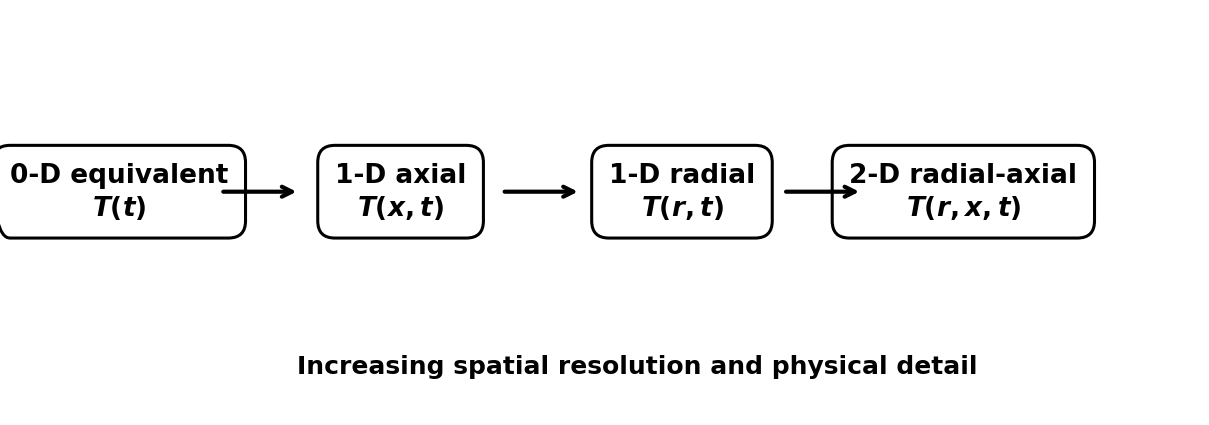

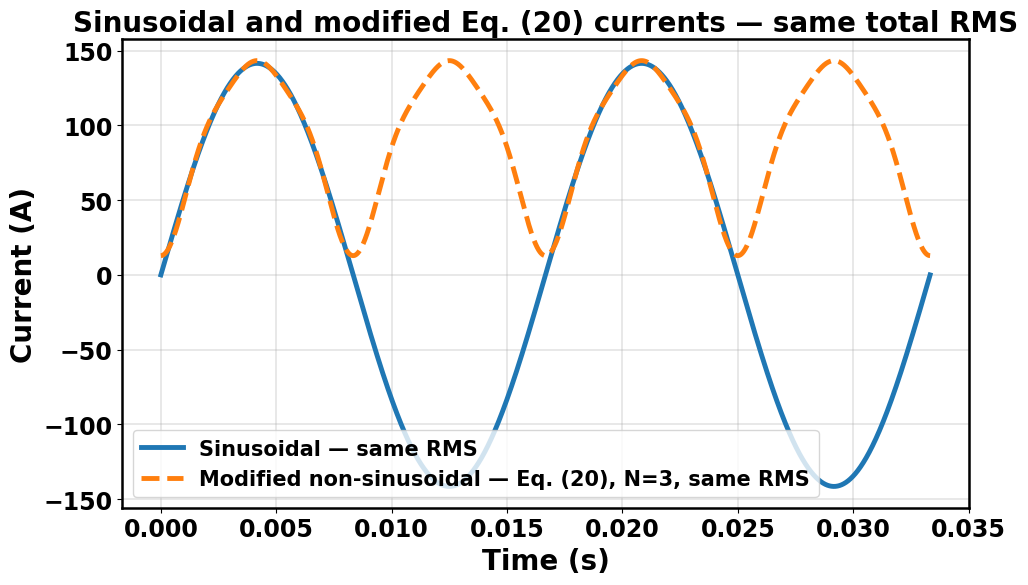

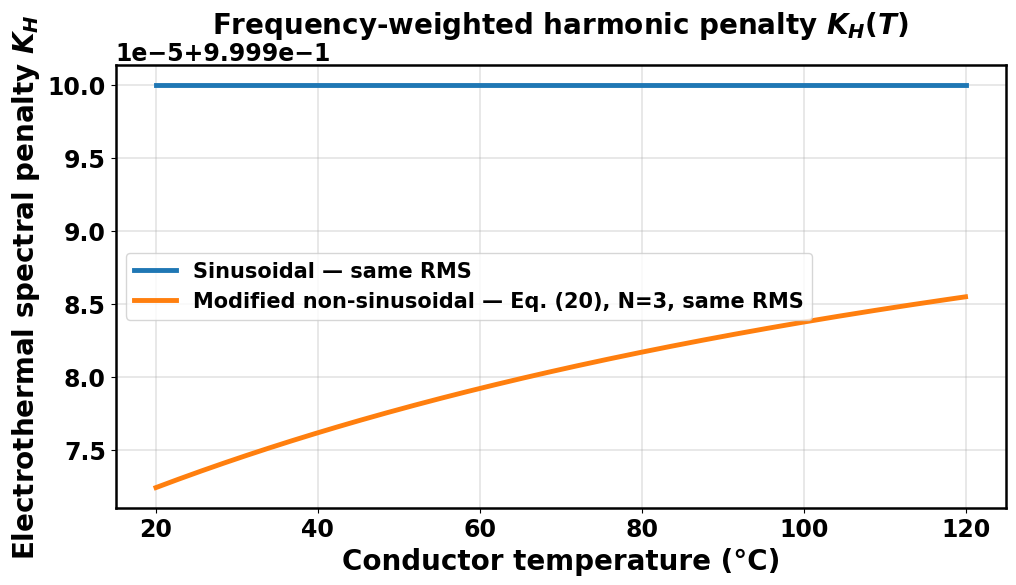


CURRENT DATA
------------------------------------------------------------------------------
Spectrum          : Sinusoidal — same RMS
Total RMS         : 100.000000 A
Peak |I(t)|       : 141.421356 A
DC component      : 0.000000 A
AC RMS component  : 100.000000 A
------------------------------------------------------------------------------

CODE 4 — 0-D / 1-D AXIAL / 1-D RADIAL / 2-D RADIAL-AXIAL
Conductor material                 : Copper
Reference area                     : 25.000 mm²
Cable length                       : 1.500 m
Ambient temperature                : 25.000 °C
Outer radius                       : 5.521 mm
Electrical excitation              : Sinusoidal — same RMS
DC current component               : 0.000000 A
AC RMS component                   : 100.000000 A
Total RMS current                  : 100.000000 A
THD (relative to h=1)              : 0.000000 %
AC ripple factor                   : not applicable
K_H at 70 °C                       : 1.00000000
-------------

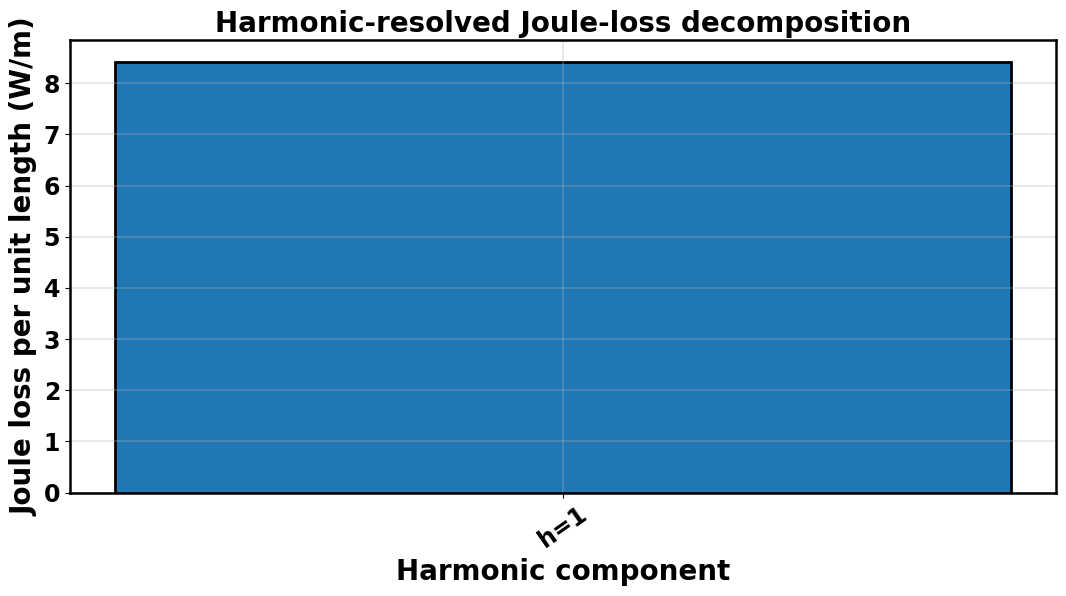

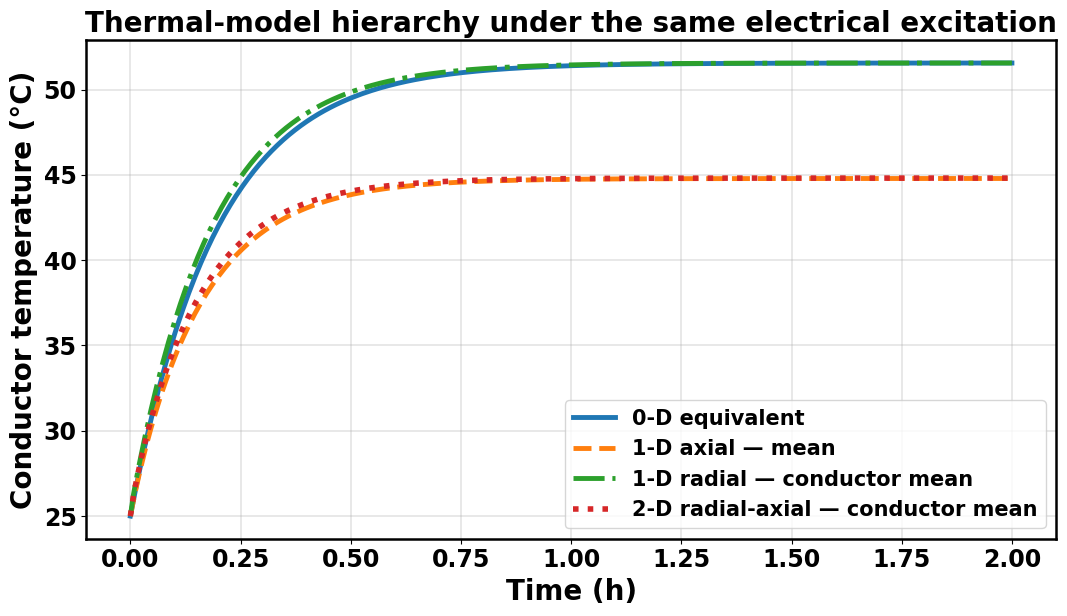

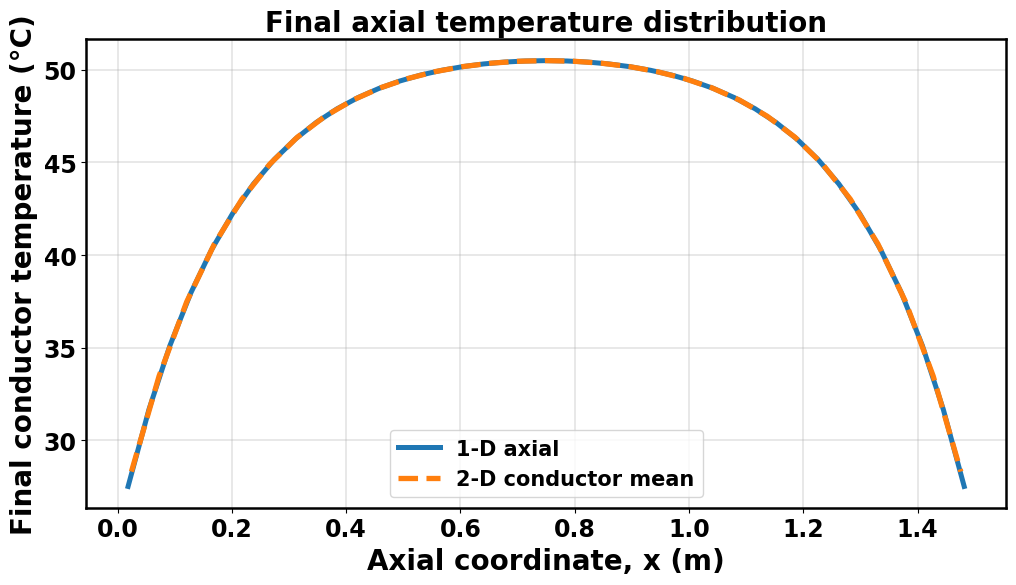

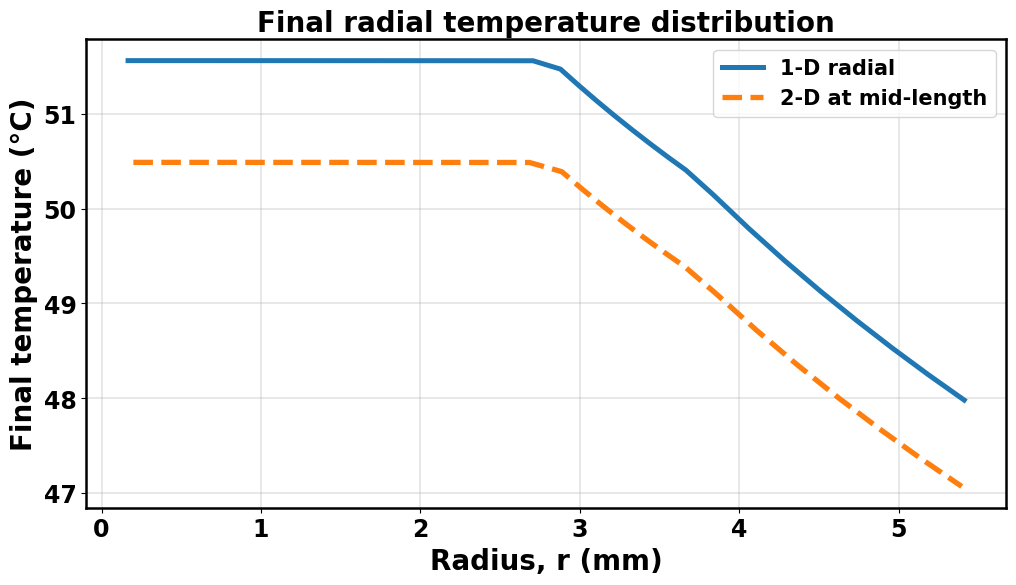

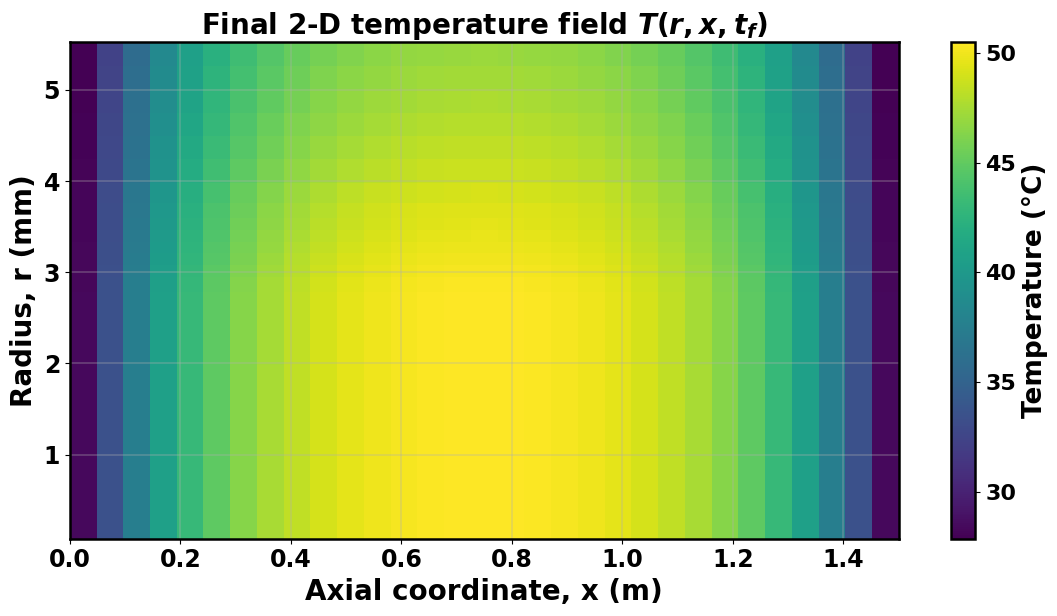

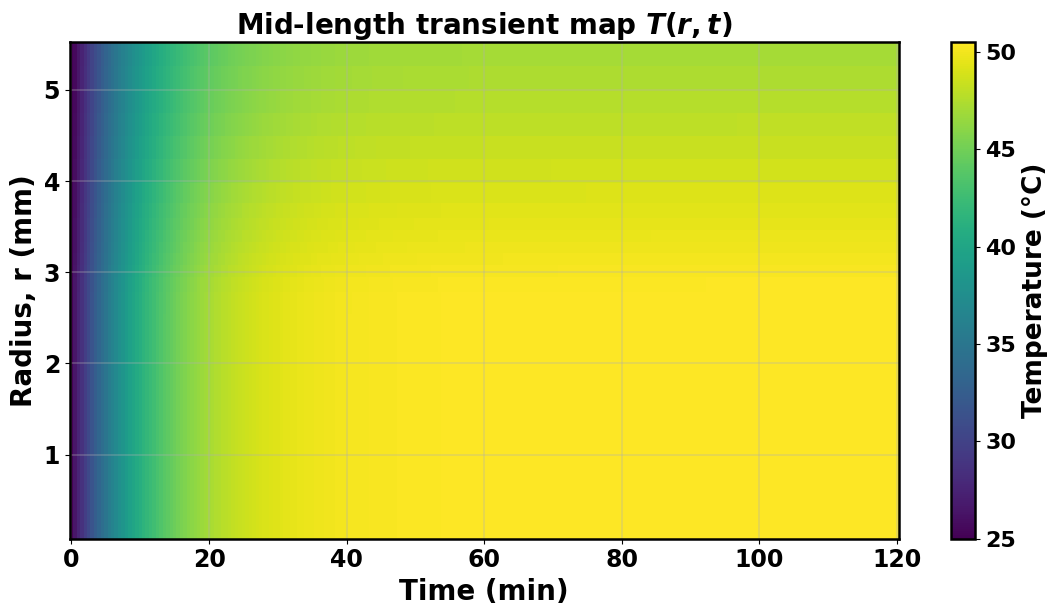

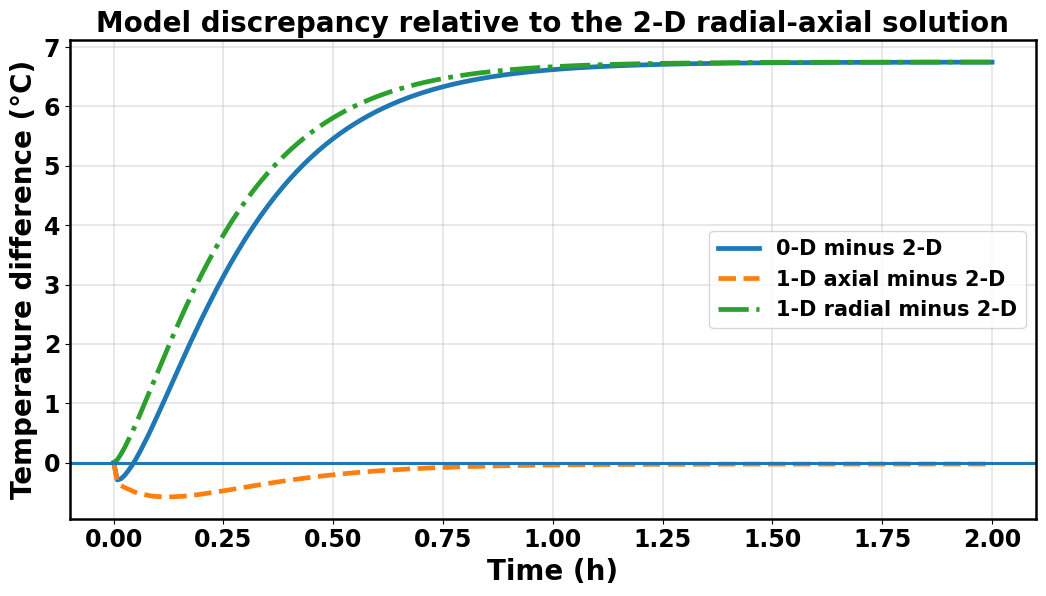


Solving dynamic ampacity for the two paper current cases...
Sinusoidal dynamic ampacity       : 150.4134 A
Modified Eq. (20) dynamic ampacity: 150.4147 A
Modified-current derating DF_M    : 1.00000879
Ampacity reduction                : -0.000879 %


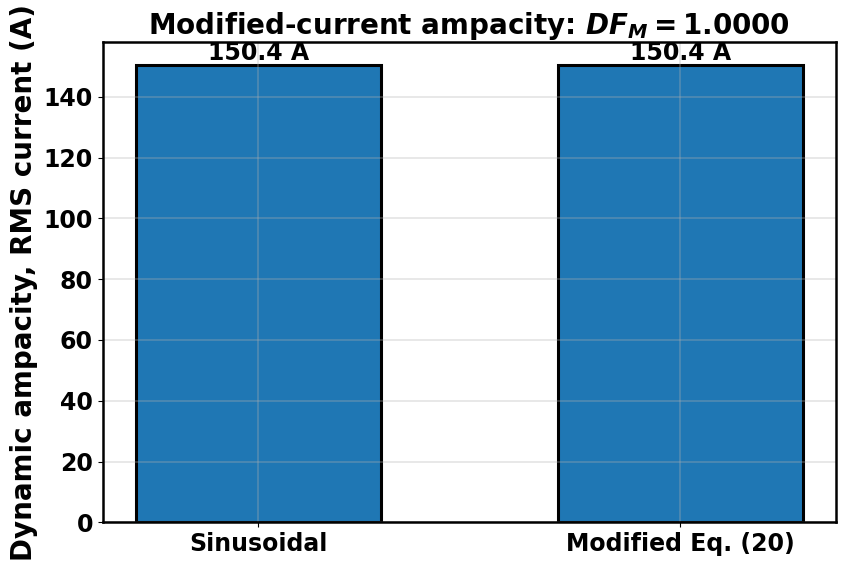


Study completed.
Electrical case used in 0-D / 1-Dx / 1-Dr / 2-D: Sinusoidal — same RMS
Core paper hierarchy: 0-D -> 1-D axial -> 1-D radial -> 2-D radial-axial.
For publication, confirm polymer properties and validate the 2-D model independently.


In [18]:
def main() -> None:
    config = StudyConfig()
    cable = build_reference_cable()

    # # -------------------------------------------------------------------------
    # The two current models used throughout the paper
    # -------------------------------------------------------------------------

    sine_base = sinusoidal_spectrum(
        config.target_total_rms_a,
        cable.fundamental_frequency_hz,
        "Sinusoidal — same RMS"
    )

    modified_base = build_modified_current_same_rms(
        target_rms_a=config.target_total_rms_a,
        f1_hz=cable.fundamental_frequency_hz,
        n_terms=config.modified_current_n_terms,
        phase_rad=config.modified_current_phase_rad
    )

    selected_case, selected_spectra = select_current_excitation(
        sine_base,
        modified_base
    )

    # -------------------------------------------------------------------------
    # Figures
    # -------------------------------------------------------------------------

    plot_model_hierarchy()

    plot_current_comparison(
        sine_base,
        modified_base,
        cable.fundamental_frequency_hz
    )

    plot_kh_vs_temperature(
        (sine_base, modified_base),
        cable
    )

    # -------------------------------------------------------------------------
    # CASE [1] or [2]: run one excitation through the complete model hierarchy.
    # -------------------------------------------------------------------------
    if selected_case in (1, 2):
        selected_spectrum = selected_spectra[0]
        print_current_data(
            selected_spectrum,
            config.modified_current_n_terms if selected_case == 2 else None,
        )
        result = solve_all_thermal_models(cable, selected_spectrum, config)

        print_summary(
            cable,
            selected_spectrum,
            result.lumped,
            result.axial,
            result.radial,
            result.model2d,
        )

        plot_harmonic_losses(harmonic_loss_breakdown(70.0, selected_spectrum, cable))
        plot_four_model_temperature_comparison(
            result.lumped, result.axial, result.radial, result.model2d
        )
        plot_axial_final_profile(result.axial, result.model2d)
        plot_radial_final_profile(result.radial, result.model2d)
        plot_2d_final_temperature_map(result.model2d)
        plot_midlength_radial_time_map(result.model2d)
        plot_model_difference_against_2d(
            result.lumped, result.axial, result.radial, result.model2d
        )

        if config.run_ampacity:
            print("\nSolving dynamic ampacity for the two paper current cases...")
            sine_ampacity = dynamic_ampacity(
                cable, sine_base, config.duration_h, model=config.ampacity_model
            )
            modified_ampacity = dynamic_ampacity(
                cable, modified_base, config.duration_h, model=config.ampacity_model
            )
            dfm = modified_ampacity.rms_current_a / sine_ampacity.rms_current_a
            reduction_percent = (1.0 - dfm) * 100.0
            print(f"Sinusoidal dynamic ampacity       : {sine_ampacity.rms_current_a:.4f} A")
            print(f"Modified Eq. (20) dynamic ampacity: {modified_ampacity.rms_current_a:.4f} A")
            print(f"Modified-current derating DF_M    : {dfm:.8f}")
            print(f"Ampacity reduction                : {reduction_percent:.6f} %")
            plot_ampacity_results(sine_ampacity, modified_ampacity)

        if config.run_2d_mesh_convergence:
            convergence = run_2d_mesh_convergence(
                cable, selected_spectrum, config.duration_h
            )
            plot_2d_mesh_convergence(convergence)

    # -------------------------------------------------------------------------
    # CASE [3]: execute BOTH currents through the same four thermal models and
    # generate the direct comparison required for the paper.
    # -------------------------------------------------------------------------
    else:
        print("\nRunning complete comparison with identical cable, RMS current, mesh and time horizon.")
        print_current_data(sine_base)
        print_current_data(modified_base, config.modified_current_n_terms)

        print("\n[1/2] Solving complete hierarchy for the sinusoidal current...")
        sine_result = solve_all_thermal_models(cable, sine_base, config)
        print_summary(
            cable, sine_base,
            sine_result.lumped, sine_result.axial,
            sine_result.radial, sine_result.model2d,
        )

        print("\n[2/2] Solving complete hierarchy for the modified Eq. (20) current...")
        modified_result = solve_all_thermal_models(cable, modified_base, config)
        print_summary(
            cable, modified_base,
            modified_result.lumped, modified_result.axial,
            modified_result.radial, modified_result.model2d,
        )

        # Individual loss decompositions and direct loss comparison.
        plot_harmonic_losses(harmonic_loss_breakdown(70.0, modified_base, cable))
        plot_total_joule_loss_comparison(cable, sine_base, modified_base)

        # Direct thermal comparisons.
        plot_four_model_current_comparison(sine_result, modified_result)
        plot_2d_mean_temperature_comparison(sine_result, modified_result)
        plot_final_axial_current_comparison(sine_result, modified_result)
        plot_final_radial_current_comparison(sine_result, modified_result)
        plot_2d_final_maps_side_by_side(sine_result, modified_result)
        plot_2d_difference_map(sine_result, modified_result)

        # Also retain the original hierarchy/detail figures for each current.
        # They are displayed sequentially; when SAVE_PLOTS=True they are saved
        # in current-specific subfolders to prevent filename overwriting.
        global OUTPUT_DIR
        base_output_dir = OUTPUT_DIR
        if SAVE_PLOTS:
            OUTPUT_DIR = base_output_dir / "sinusoidal"
        plot_four_model_temperature_comparison(
            sine_result.lumped, sine_result.axial, sine_result.radial, sine_result.model2d
        )
        plot_axial_final_profile(sine_result.axial, sine_result.model2d)
        plot_radial_final_profile(sine_result.radial, sine_result.model2d)
        plot_2d_final_temperature_map(sine_result.model2d)
        plot_midlength_radial_time_map(sine_result.model2d)
        plot_model_difference_against_2d(
            sine_result.lumped, sine_result.axial, sine_result.radial, sine_result.model2d
        )

        if SAVE_PLOTS:
            OUTPUT_DIR = base_output_dir / "modified_eq20"
        plot_four_model_temperature_comparison(
            modified_result.lumped, modified_result.axial,
            modified_result.radial, modified_result.model2d
        )
        plot_axial_final_profile(modified_result.axial, modified_result.model2d)
        plot_radial_final_profile(modified_result.radial, modified_result.model2d)
        plot_2d_final_temperature_map(modified_result.model2d)
        plot_midlength_radial_time_map(modified_result.model2d)
        plot_model_difference_against_2d(
            modified_result.lumped, modified_result.axial,
            modified_result.radial, modified_result.model2d
        )
        OUTPUT_DIR = base_output_dir

        sine_ampacity = None
        modified_ampacity = None
        if config.run_ampacity:
            print("\nSolving dynamic ampacity comparison...")
            sine_ampacity = dynamic_ampacity(
                cable, sine_base, config.duration_h, model=config.ampacity_model
            )
            modified_ampacity = dynamic_ampacity(
                cable, modified_base, config.duration_h, model=config.ampacity_model
            )
            dfm = modified_ampacity.rms_current_a / sine_ampacity.rms_current_a
            reduction_percent = (1.0 - dfm) * 100.0
            print(f"Sinusoidal dynamic ampacity       : {sine_ampacity.rms_current_a:.4f} A")
            print(f"Modified Eq. (20) dynamic ampacity: {modified_ampacity.rms_current_a:.4f} A")
            print(f"Modified-current derating DF_M    : {dfm:.8f}")
            print(f"Ampacity reduction                : {reduction_percent:.6f} %")
            plot_ampacity_results(sine_ampacity, modified_ampacity)

        print_sinusoidal_modified_comparison(
            cable,
            sine_result,
            modified_result,
            sine_ampacity,
            modified_ampacity,
        )

        if config.run_2d_mesh_convergence:
            print("\n2-D mesh convergence — sinusoidal current")
            conv_sin = run_2d_mesh_convergence(cable, sine_base, config.duration_h)
            plot_2d_mesh_convergence(conv_sin)
            print("\n2-D mesh convergence — modified current")
            conv_mod = run_2d_mesh_convergence(cable, modified_base, config.duration_h)
            plot_2d_mesh_convergence(conv_mod)

    if config.run_thd_derating:
        print(
            "\nNOTE: the generic THD sweep is skipped for the Eq. (20) current because "
            "it contains DC plus even harmonics and no h=1 component. Use a Fourier-order "
            "or ripple-factor study for this waveform instead."
        )

    print("\nStudy completed.")
    if selected_case == 3:
        print("Electrical cases: sinusoidal AND modified Eq. (20), same total RMS.")
    else:
        print(f"Electrical case used in 0-D / 1-Dx / 1-Dr / 2-D: {selected_spectra[0].name}")
    print("Core paper hierarchy: 0-D -> 1-D axial -> 1-D radial -> 2-D radial-axial.")
    print("For publication, confirm polymer properties and validate the 2-D model independently.")


if __name__ == "__main__":
    main()
